<div style="background: linear-gradient(135deg, #0d1117 0%, #1a1a2e 40%, #16213e 70%, #0f3460 100%); padding: 65px 45px; border-radius: 20px; text-align: center; margin-bottom: 30px;">
  <div style="font-size: 3.5em; margin-bottom: 10px;">🎵</div>
  <h1 style="color: #1DB954; font-size: 2.8em; font-family: Georgia, serif; margin: 0; letter-spacing: 2px; text-shadow: 0 0 20px rgba(29,185,84,0.4);">SPOTIFY TOP 100</h1>
  <h2 style="color: #f0f0f0; font-size: 1.3em; font-family: Georgia, serif; margin: 12px 0 0 0; font-weight: 300; letter-spacing: 6px;">A DATA STORY OF MUSIC TRENDS</h2>
  <hr style="border: 1px solid #1DB954; width: 55%; margin: 25px auto;"/>
  <p style="color: #ccc; font-size: 1.05em; font-style: italic;">Exploratory Data Analysis · Statistics · Regression</p>
  <p style="color: #888; font-size: 0.9em;">2020 – 2024 &nbsp;·&nbsp; 100 Chart-Topping Songs &nbsp;·&nbsp; Spotify Audio Features</p>
</div>

## 📖 The Story

> *Spotify has over 600 million users and streams billions of songs daily. But what actually makes a song a **hit**? Is it the energy? The danceability? The mood? Today we dive into the data behind the biggest tracks of the past 5 years.*

Using Spotify's audio features — quantitative measurements of each song's musical DNA — we'll answer:

- 🎤 **Who** dominated the charts? Which artists and genres ruled?
- 📈 **How have music trends shifted** from 2020 to 2024?
- 💃 **What makes a hit?** Danceability, energy, valence — what matters most?
- 🔊 **Has pop gotten louder, faster, sadder?** Track the evolution of sound.
- 🤖 **Can we predict streams?** Build a regression model to quantify what drives popularity.

---

## 🗺️ Roadmap

```
PART 1 ─── Setup & Dataset Introduction
PART 2 ─── Descriptive Statistics          ← measures of center, spread, shape
PART 3 ─── Exploratory Data Analysis       ← distributions, trends, genre breakdowns
PART 4 ─── Correlation Analysis            ← which audio features matter most
PART 5 ─── Feature Engineering             ← preparing data for modeling
PART 6 ─── Simple Linear Regression        ← one predictor, the math, the intuition
PART 7 ─── Multiple Linear Regression      ← all predictors, model performance
PART 8 ─── Regression Diagnostics          ← residuals, assumptions, quality
PART 9 ─── Conclusions                     ← what the data tells us about hits
```

---
# 📦 PART 1 — Setup & Data Loading

In [1]:
# ════════════════════════════════════════════════════════════════════
#  IMPORTS
# ════════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

from scipy import stats
from scipy.stats import skew, kurtosis, pearsonr, shapiro

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ── Global Plot Style — Spotify-inspired ────────────────────────────
plt.style.use('dark_background')
plt.rcParams.update({
    'figure.facecolor':  '#0d1117',
    'axes.facecolor':    '#1a1a2e',
    'axes.edgecolor':    '#333',
    'grid.color':        '#2a2a3e',
    'grid.linestyle':    '--',
    'grid.alpha':        0.5,
    'text.color':        '#e8e8e8',
    'axes.labelcolor':   '#e8e8e8',
    'xtick.color':       '#aaa',
    'ytick.color':       '#aaa',
    'font.size':         11,
    'axes.titlesize':    13,
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

# Spotify-inspired color palette
C = {
    'green':   '#1DB954',  # Spotify green
    'white':   '#FFFFFF',
    'black':   '#191414',  # Spotify black
    'gold':    '#FFD700',
    'pink':    '#FF6B9D',
    'blue':    '#00D4FF',
    'purple':  '#9B5DE5',
    'coral':   '#FF6B6B',
    'mint':    '#00C9A7',
    'orange':  '#FFA500',
    'genre': ['#1DB954','#00D4FF','#FF6B9D','#FFD700','#9B5DE5','#FF6B6B','#FFA500','#00C9A7'],
    'years':  ['#3D9BE9','#1DB954','#FFD700','#FF6B9D','#9B5DE5'],
}

print("✅ Libraries loaded successfully!")
print(f"   pandas  {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

✅ Libraries loaded successfully!
   pandas  3.0.2 | numpy 2.4.4 | seaborn 0.13.2


<div style="background:#1a1a2e; padding:18px 22px; border-radius:12px; border-left:5px solid #1DB954;">

## 🎧 The Dataset: Spotify Top 100 Songs (2020–2024)

We're working with **98 chart-topping songs** across 5 years. Each row is one track, with Spotify's proprietary **audio features** — numerical measurements of musical qualities.

| Feature | Description | Range |
|---------|-------------|-------|
| `danceability` | How suitable for dancing (rhythm, beat strength) | 0.0 – 1.0 |
| `energy` | Intensity & activity (fast, loud, noisy = high) | 0.0 – 1.0 |
| `valence` | Musical positiveness (happy/euphoric vs sad/angry) | 0.0 – 1.0 |
| `tempo` | Estimated beats per minute (BPM) | ~60–200 |
| `loudness` | Overall loudness in dB (negative values) | ~-20 to 0 |
| `speechiness` | Presence of spoken words | 0.0 – 1.0 |
| `acousticness` | Confidence the track is acoustic | 0.0 – 1.0 |
| `instrumentalness` | Predicts if track has no vocals | 0.0 – 1.0 |
| `streams_millions` | Spotify streams in millions ← **TARGET** | Numeric |

</div>

In [2]:
# ── Load Dataset ─────────────────────────────────────────────────────
df = pd.read_csv('spotify_top100_2020_2024.csv')

print("🎵 Dataset loaded!")
print(f"   Shape: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"   Years: {df['year'].min()} – {df['year'].max()}")
print(f"   Genres: {df['genre'].nunique()} unique")
print(f"   Missing values: {df.isnull().sum().sum()}")
print()
df.head(10)

🎵 Dataset loaded!
   Shape: 98 rows × 17 columns
   Years: 2020 – 2024
   Genres: 10 unique
   Missing values: 0



,title,artist,year,streams_millions,danceability,energy,valence,tempo,loudness,speechiness,acousticness,instrumentalness,duration_sec,explicit,genre,duration_min,popularity_score
0,Blinding Lights,The Weeknd,2020,3510,0.514,0.730,0.334,171.0,-5.934,0.0598,0.00146,0.000095,200,0,Pop,3.33,100.0
1,Watermelon Sugar,Harry Styles,2020,2100,0.548,0.816,0.557,95.4,-4.209,0.0354,0.12200,0.000002,174,0,Pop,2.90,59.8
2,Rockstar,DaBaby ft. Roddy Ricch,2020,1800,0.746,0.690,0.493,180.0,-7.956,0.1310,0.01070,0.000000,178,1,Hip-Hop,2.97,51.3
3,Say So,Doja Cat,2020,1650,0.754,0.622,0.826,111.0,-4.878,0.0636,0.01860,0.000000,237,0,Pop,3.95,47.0
4,Savage,Megan Thee Stallion ft. Beyonce,2020,1540,0.843,0.612,0.616,150.0,-5.543,0.1750,0.00765,0.000000,211,1,Hip-Hop,3.52,43.9
5,Roses,SAINt JHN,2020,1420,0.714,0.681,0.522,99.0,-5.734,0.0563,0.17500,0.000000,192,0,Pop,3.20,40.5
6,Life Is Good,Future ft. Drake,2020,1380,0.798,0.620,0.527,78.0,-7.282,0.1330,0.06350,0.000000,244,1,Hip-Hop,4.07,39.3
7,The Box,Roddy Ricch,2020,1320,0.762,0.576,0.261,139.0,-7.652,0.2040,0.03740,0.000000,197,1,Hip-Hop,3.28,37.6
8,Toosie Slide,Drake,2020,1290,0.803,0.543,0.448,100.0,-8.137,0.1370,0.23400,0.000000,231,1,Hip-Hop,3.85,36.8
9,Don't Start Now,Dua Lipa,2020,1870,0.789,0.791,0.535,124.0,-4.369,0.0454,0.01610,0.000000,183,0,Pop,3.05,53.3


---
# 📏 PART 2 — Descriptive Statistics

<div style="background:#1a1a2e; padding:18px 22px; border-radius:10px; border-left:5px solid #1DB954;">

**Descriptive statistics** summarize the main features of our dataset. We cover:

- **Measures of Central Tendency** — *Where is the center?* (mean, median, mode)
- **Measures of Spread** — *How variable is the data?* (std, variance, IQR)
- **Measures of Shape** — *What does the distribution look like?* (skewness, kurtosis)
- **Measures of Position** — *Where does a value rank?* (percentiles, z-scores)

</div>

In [3]:
# ── 2.1 Built-in describe() ───────────────────────────────────────────
audio_features = ['danceability','energy','valence','tempo','loudness',
                  'speechiness','acousticness','streams_millions','duration_min']

print("="*70)
print(" PANDAS DESCRIBE() — Audio Features Summary")
print("="*70)
df[audio_features].describe().round(3)

 PANDAS DESCRIBE() — Audio Features Summary


,danceability,energy,valence,tempo,loudness,speechiness,acousticness,streams_millions,duration_min
count,98.000,98.000,98.000,98.000,98.000,98.000,98.000,98.000,98.000
mean,0.686,0.683,0.597,115.053,-6.198,0.075,0.119,1589.592,3.277
std,0.099,0.113,0.189,24.848,1.815,0.044,0.162,549.871,0.556
min,0.416,0.258,0.170,74.000,-14.454,0.029,0.001,780.000,1.970
25%,0.612,0.619,0.444,97.000,-7.270,0.048,0.014,1200.000,2.920
50%,0.704,0.692,0.614,111.500,-5.857,0.061,0.046,1450.000,3.290
75%,0.764,0.758,0.742,128.250,-4.892,0.087,0.177,1852.500,3.617
max,0.865,0.949,0.933,180.000,-3.234,0.266,0.869,3510.000,5.000


In [4]:
# ── 2.2 Extended Descriptive Statistics Table ─────────────────────────
from scipy.stats import skew, kurtosis

def extended_stats(df, cols):
    results = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        results.append({
            'Feature':  col,
            'Count':    len(s),
            'Mean':     round(s.mean(), 3),
            'Median':   round(s.median(), 3),
            'Std Dev':  round(s.std(), 3),
            'Variance': round(s.var(), 3),
            'Min':      round(s.min(), 3),
            'Max':      round(s.max(), 3),
            'Range':    round(s.max() - s.min(), 3),
            'IQR':      round(q3 - q1, 3),
            'Skewness': round(skew(s), 3),
            'Kurtosis': round(kurtosis(s), 3),
            'CV (%)':   round(s.std() / s.mean() * 100, 1) if s.mean() != 0 else 'N/A',
        })
    return pd.DataFrame(results).set_index('Feature')

stats_table = extended_stats(df, audio_features)
print("EXTENDED DESCRIPTIVE STATISTICS")
print("CV = Coefficient of Variation — measures relative spread")
stats_table

EXTENDED DESCRIPTIVE STATISTICS
CV = Coefficient of Variation — measures relative spread


,Count,Mean,Median,Std Dev,Variance,Min,Max,Range,IQR,Skewness,Kurtosis,CV (%)
Feature,,,,,,,,,,,,
danceability,98,0.686,0.704,0.099,0.010,0.416,0.865,0.449,0.152,-0.483,-0.420,14.5
energy,98,0.683,0.692,0.113,0.013,0.258,0.949,0.691,0.138,-0.608,1.381,16.6
valence,98,0.597,0.614,0.189,0.036,0.170,0.933,0.763,0.299,-0.273,-0.685,31.7
tempo,98,115.053,111.500,24.848,617.416,74.000,180.000,106.000,31.250,0.655,0.041,21.6
loudness,98,-6.198,-5.857,1.815,3.293,-14.454,-3.234,11.220,2.378,-1.279,3.070,-29.3
speechiness,98,0.075,0.061,0.044,0.002,0.029,0.266,0.237,0.039,1.930,4.325,58.2
acousticness,98,0.119,0.046,0.162,0.026,0.001,0.869,0.868,0.163,2.129,5.244,135.8
streams_millions,98,1589.592,1450.000,549.871,302358.595,780.000,3510.000,2730.000,652.500,1.210,1.425,34.6
duration_min,98,3.277,3.290,0.556,0.309,1.970,5.000,3.030,0.697,0.114,0.136,17.0


### 📝 Key Observations from Descriptive Statistics

| Metric | Value | Insight |
|--------|-------|---------|
| **Avg Danceability** | ~0.69 | Top hits are highly danceable — rhythm is essential |
| **Avg Energy** | ~0.68 | Chart-toppers are energetic and intense |
| **Avg Valence** | ~0.57 | Slight positive bias — but many sad hits exist |
| **Avg Tempo** | ~111 BPM | Mid-tempo dominates; neither too slow nor too frantic |
| **Avg Streams** | ~1,514M | Massive range — a few songs dominate billions of plays |
| **Skewness (Streams)** | Positive | Right-skewed: a few mega-hits pull the average up |

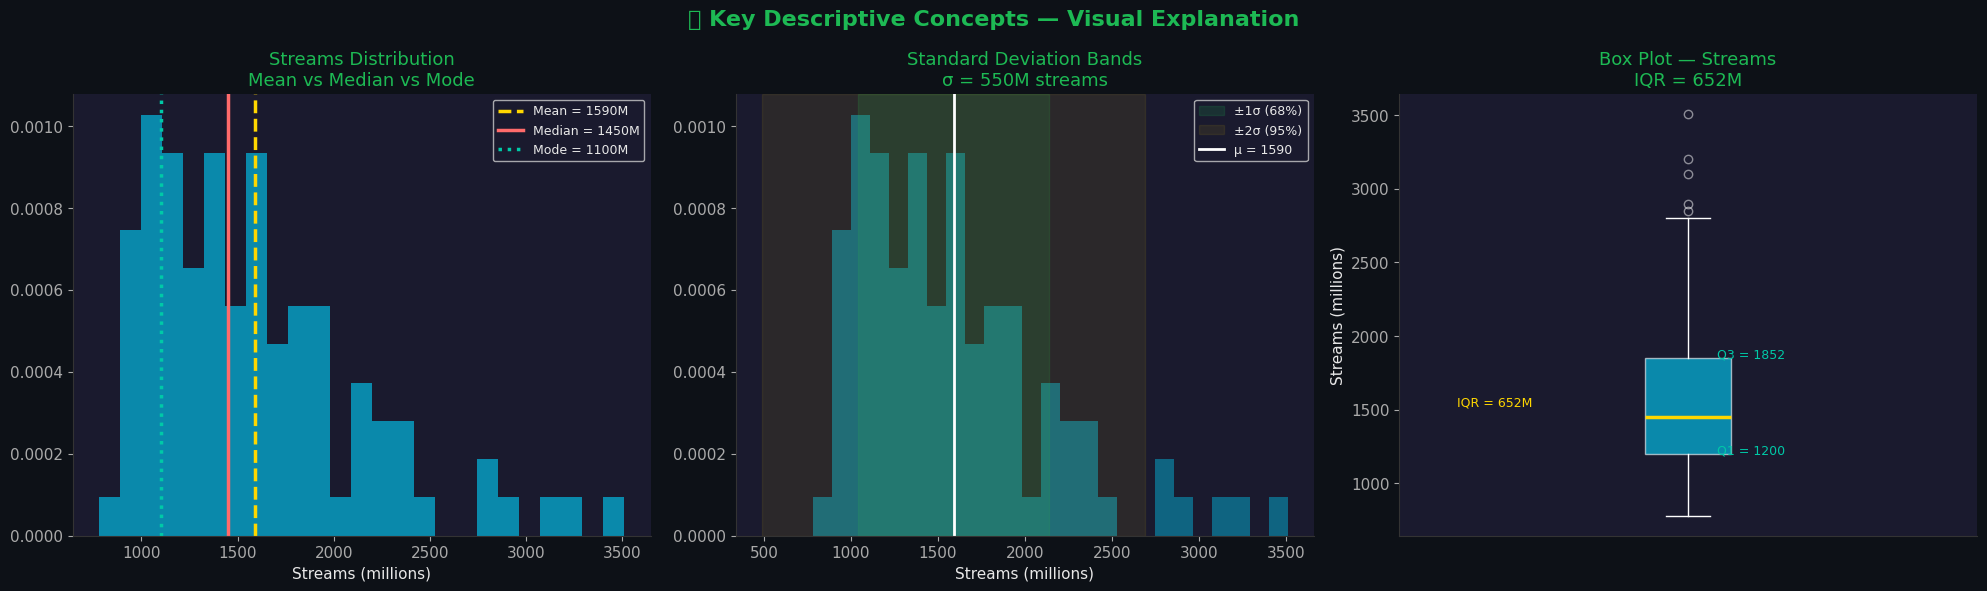


📌 Note: Streams are right-skewed (skew = 1.21) — a few megahits dominate!


In [5]:
# ── 2.3 Visual Explanation of Key Descriptive Concepts ───────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('📏 Key Descriptive Concepts — Visual Explanation',
             fontsize=16, fontweight='bold', color=C['green'])

col = 'streams_millions'
data = df[col].dropna()

# (a) Mean vs Median vs Mode
axes[0].hist(data, bins=25, color=C['blue'], alpha=0.6, edgecolor='none', density=True)
axes[0].axvline(data.mean(),   color=C['gold'],  lw=2.5, ls='--', label=f'Mean = {data.mean():.0f}M')
axes[0].axvline(data.median(), color=C['coral'], lw=2.5, ls='-',  label=f'Median = {data.median():.0f}M')
axes[0].axvline(data.mode()[0],color=C['mint'],  lw=2.5, ls=':',  label=f'Mode = {data.mode()[0]:.0f}M')
axes[0].set_title('Streams Distribution\nMean vs Median vs Mode', color=C['green'])
axes[0].set_xlabel('Streams (millions)')
axes[0].legend(fontsize=9)

# (b) Standard Deviation bands
mu, sigma = data.mean(), data.std()
x = np.linspace(data.min(), data.max(), 300)
axes[1].hist(data, bins=25, color=C['blue'], alpha=0.4, density=True, edgecolor='none')
axes[1].axvspan(mu - sigma, mu + sigma, alpha=0.15, color=C['green'], label=f'±1σ (68%)')
axes[1].axvspan(mu - 2*sigma, mu + 2*sigma, alpha=0.08, color=C['gold'], label=f'±2σ (95%)')
axes[1].axvline(mu, color=C['white'], lw=2, label=f'μ = {mu:.0f}')
axes[1].set_title(f'Standard Deviation Bands\nσ = {sigma:.0f}M streams', color=C['green'])
axes[1].set_xlabel('Streams (millions)')
axes[1].legend(fontsize=9)

# (c) Box plot with IQR annotation
bp = axes[2].boxplot(data, vert=True, patch_artist=True,
                     medianprops=dict(color=C['gold'], lw=2.5),
                     flierprops=dict(marker='o', color=C['coral'], alpha=0.5))
bp['boxes'][0].set_facecolor(C['blue'])
bp['boxes'][0].set_alpha(0.6)
q1, q3 = data.quantile(0.25), data.quantile(0.75)
iqr = q3 - q1
axes[2].annotate(f'Q3 = {q3:.0f}', xy=(1.05, q3), fontsize=9, color=C['mint'])
axes[2].annotate(f'Q1 = {q1:.0f}', xy=(1.05, q1), fontsize=9, color=C['mint'])
axes[2].annotate(f'IQR = {iqr:.0f}M', xy=(0.6, (q1+q3)/2), fontsize=9, color=C['gold'])
axes[2].set_title(f'Box Plot — Streams\nIQR = {iqr:.0f}M', color=C['green'])
axes[2].set_ylabel('Streams (millions)')
axes[2].set_xticks([])

plt.tight_layout()
plt.savefig('descriptive_concepts.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print(f"\n📌 Note: Streams are right-skewed (skew = {skew(data):.2f}) — a few megahits dominate!")

---
# 🔍 PART 3 — Exploratory Data Analysis

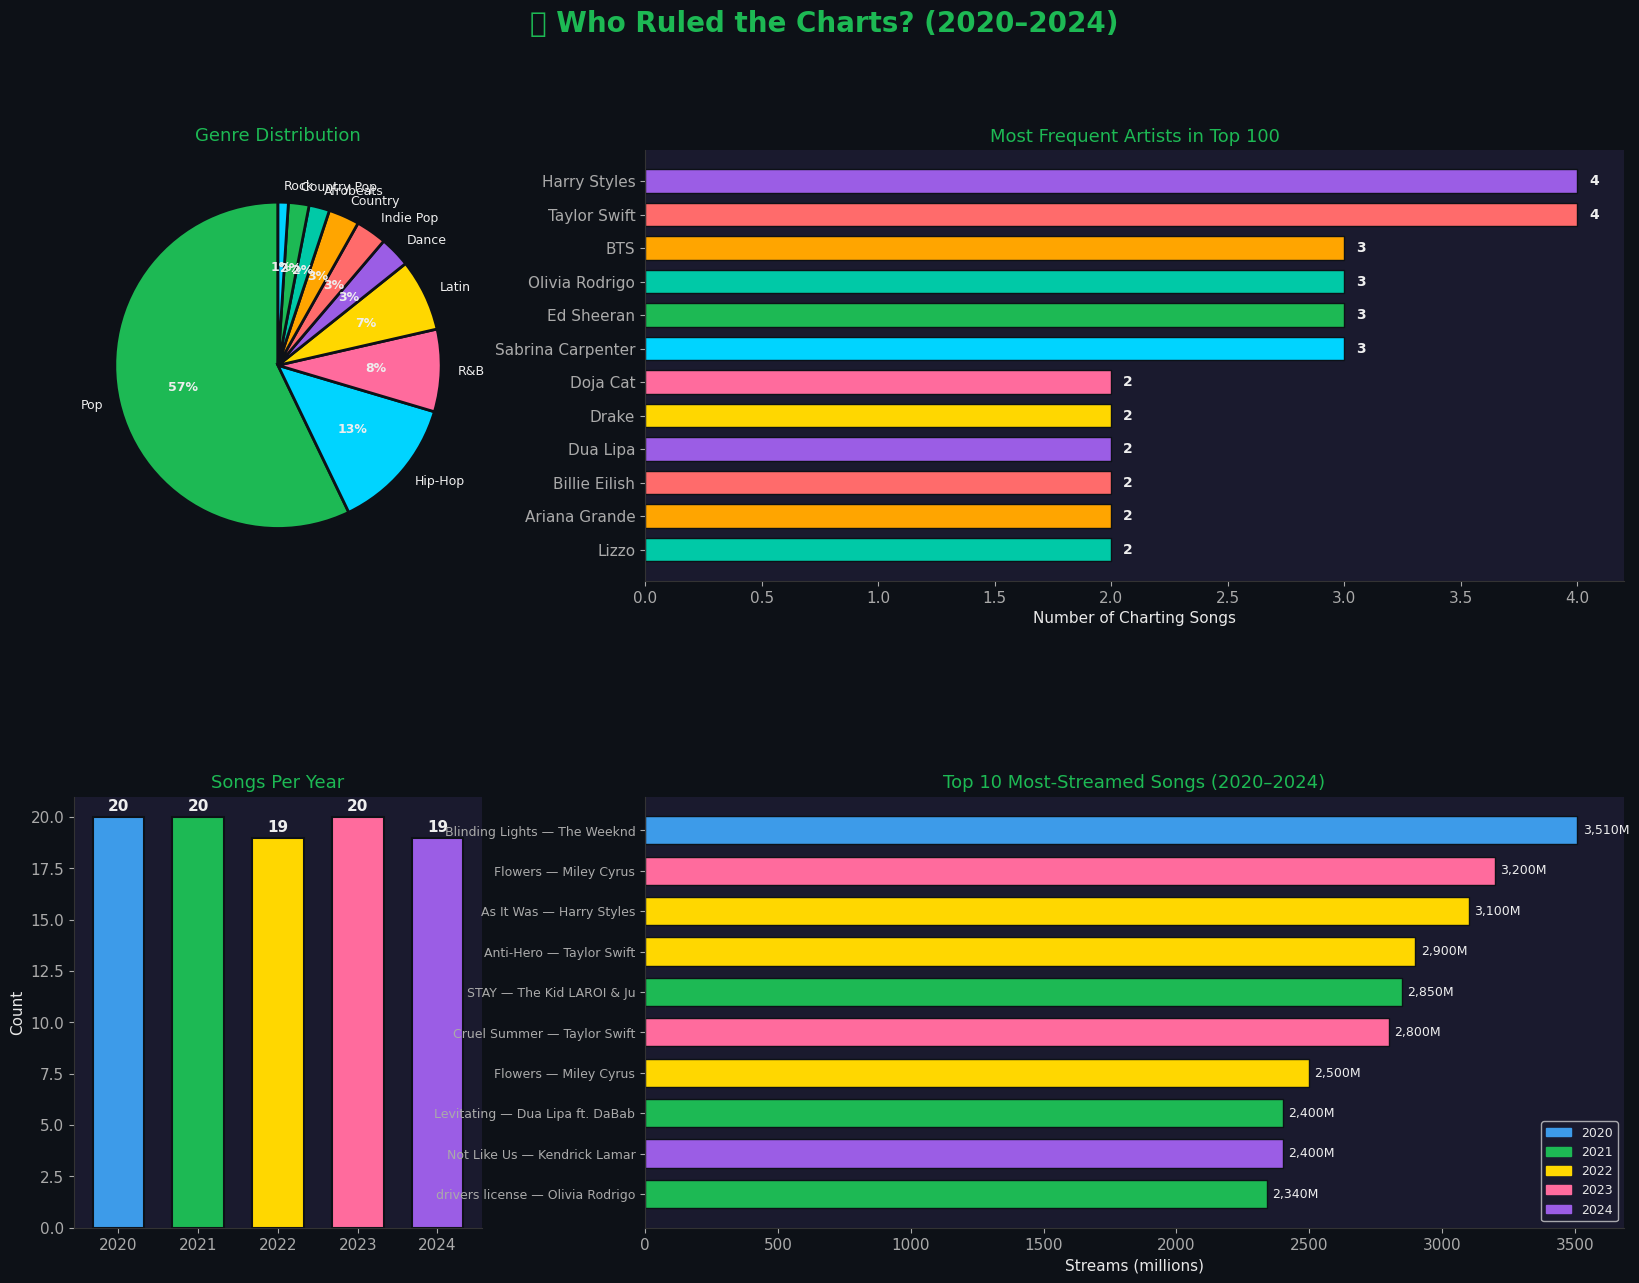

In [6]:
# ── 3.1 Genre & Artist Overview ───────────────────────────────────────
fig = plt.figure(figsize=(20, 14))
fig.suptitle('🎤 Who Ruled the Charts? (2020–2024)', fontsize=20,
             fontweight='bold', color=C['green'], y=0.98)
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.50, wspace=0.40)

# Genre distribution
ax1 = fig.add_subplot(gs[0, 0])
genre_counts = df['genre'].value_counts()
colors_g = C['genre'][:len(genre_counts)]
wedges, texts, autotexts = ax1.pie(
    genre_counts.values, labels=genre_counts.index,
    colors=colors_g, autopct='%1.0f%%', startangle=90,
    wedgeprops={'edgecolor':'#0d1117','linewidth':2},
    textprops={'color':'#eee','fontsize':9}
)
for at in autotexts: at.set_fontsize(9); at.set_fontweight('bold')
ax1.set_title('Genre Distribution', color=C['green'], fontsize=13, pad=15)

# Top artists by appearances
ax2 = fig.add_subplot(gs[0, 1:])
artist_appearances = df['artist'].value_counts().head(12)
bars = ax2.barh(artist_appearances.index[::-1], artist_appearances.values[::-1],
                color=C['genre'][:12][::-1], height=0.7, edgecolor='#0d1117')
for bar in bars:
    ax2.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
             str(int(bar.get_width())), va='center', color='#eee', fontsize=10, fontweight='bold')
ax2.set_title('Most Frequent Artists in Top 100', color=C['green'], fontsize=13)
ax2.set_xlabel('Number of Charting Songs')

# Year-by-year song count
ax3 = fig.add_subplot(gs[1, 0])
year_counts = df['year'].value_counts().sort_index()
bars3 = ax3.bar(year_counts.index, year_counts.values,
                color=C['years'], width=0.65, edgecolor='#0d1117', linewidth=1.5)
for bar in bars3:
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             str(int(bar.get_height())), ha='center', color='#eee', fontweight='bold')
ax3.set_title('Songs Per Year', color=C['green'], fontsize=13)
ax3.set_ylabel('Count')

# Top 10 songs by streams
ax4 = fig.add_subplot(gs[1, 1:])
top10 = df.nlargest(10, 'streams_millions')[['title','artist','streams_millions','year']].reset_index(drop=True)
colors_top = [C['years'][y-2020] for y in top10['year']]
bars4 = ax4.barh(range(10), top10['streams_millions'][::-1],
                 color=colors_top[::-1], height=0.7, edgecolor='#0d1117')
labels_top = [f"{r['title'][:22]} — {r['artist'][:18]}" for _, r in top10.iterrows()]
ax4.set_yticks(range(10))
ax4.set_yticklabels(labels_top[::-1], fontsize=9)
for bar in bars4:
    ax4.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2,
             f"{bar.get_width():,.0f}M", va='center', color='#eee', fontsize=9)
ax4.set_title('Top 10 Most-Streamed Songs (2020–2024)', color=C['green'], fontsize=13)
ax4.set_xlabel('Streams (millions)')

# Year legend
year_handles = [mpatches.Patch(color=C['years'][i], label=str(2020+i)) for i in range(5)]
ax4.legend(handles=year_handles, loc='lower right', fontsize=9)

plt.savefig('chart_overview.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

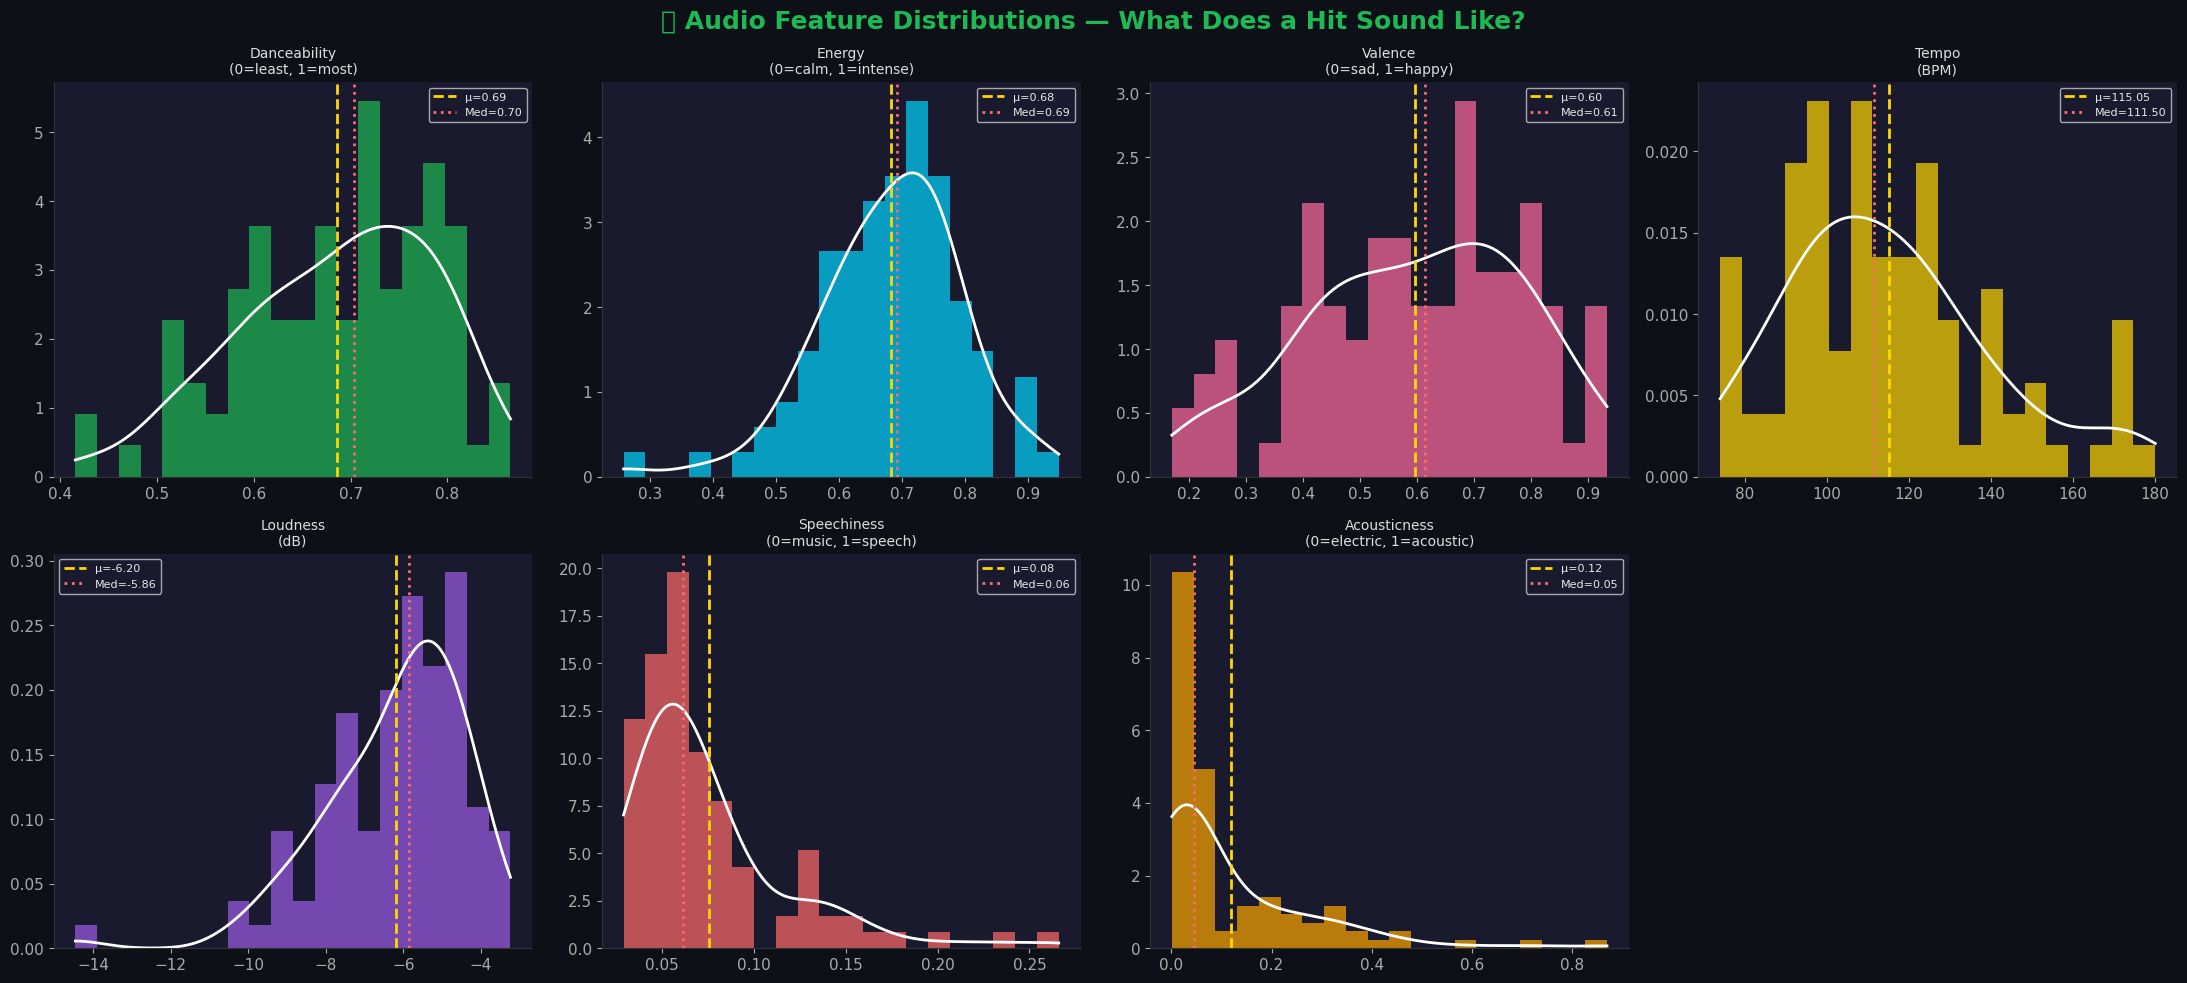

In [7]:
# ── 3.2 Audio Feature Distributions ──────────────────────────────────
features = ['danceability','energy','valence','tempo','loudness','speechiness','acousticness']
feature_labels = {
    'danceability': 'Danceability\n(0=least, 1=most)',
    'energy':       'Energy\n(0=calm, 1=intense)',
    'valence':      'Valence\n(0=sad, 1=happy)',
    'tempo':        'Tempo\n(BPM)',
    'loudness':     'Loudness\n(dB)',
    'speechiness':  'Speechiness\n(0=music, 1=speech)',
    'acousticness': 'Acousticness\n(0=electric, 1=acoustic)',
}

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle('🎵 Audio Feature Distributions — What Does a Hit Sound Like?',
             fontsize=18, fontweight='bold', color=C['green'])
axes = axes.flatten()

for i, feat in enumerate(features):
    data_f = df[feat].dropna()
    ax = axes[i]
    ax.hist(data_f, bins=20, color=C['genre'][i], alpha=0.7, edgecolor='none', density=True)
    
    # KDE curve
    from scipy.stats import gaussian_kde
    kde = gaussian_kde(data_f)
    x_range = np.linspace(data_f.min(), data_f.max(), 200)
    ax.plot(x_range, kde(x_range), color='white', lw=2)
    
    ax.axvline(data_f.mean(), color=C['gold'], lw=2, ls='--', label=f'μ={data_f.mean():.2f}')
    ax.axvline(data_f.median(), color=C['coral'], lw=2, ls=':', label=f'Med={data_f.median():.2f}')
    ax.set_title(feature_labels[feat], color='#ddd', fontsize=10)
    ax.legend(fontsize=8)

axes[-1].set_visible(False)
plt.tight_layout()
plt.savefig('audio_distributions.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

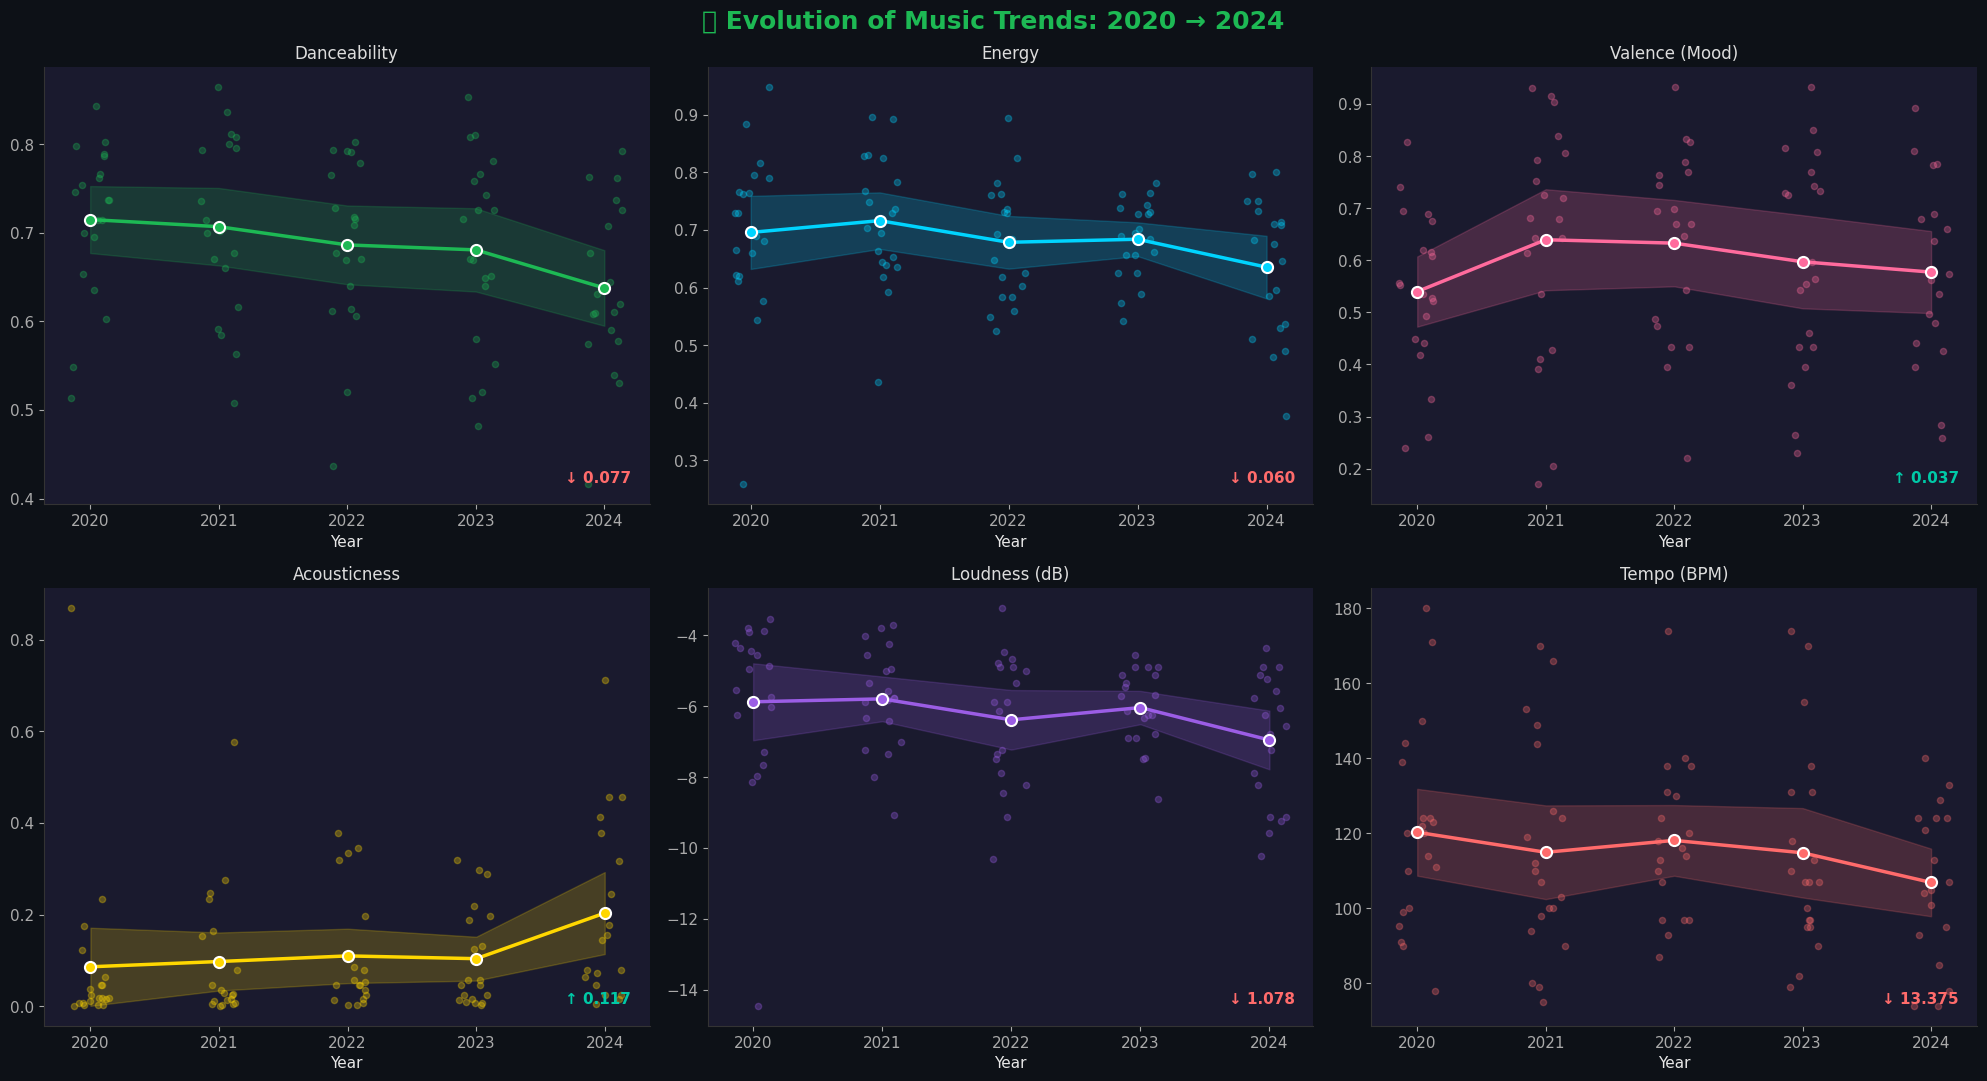


📌 Shaded band = 95% Confidence Interval around the yearly mean
   ↑↓ arrows show net change from 2020 to 2024


In [8]:
# ── 3.3 How Have Audio Trends Changed Over the Years? ─────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle('📈 Evolution of Music Trends: 2020 → 2024',
             fontsize=18, fontweight='bold', color=C['green'])
axes = axes.flatten()

trend_features = ['danceability','energy','valence','acousticness','loudness','tempo']
trend_labels    = ['Danceability','Energy','Valence (Mood)','Acousticness','Loudness (dB)','Tempo (BPM)']

for i, (feat, label) in enumerate(zip(trend_features, trend_labels)):
    ax = axes[i]
    
    # Yearly means with CI
    yearly = df.groupby('year')[feat].agg(['mean','std','count']).reset_index()
    yearly['se'] = yearly['std'] / np.sqrt(yearly['count'])
    yearly['ci'] = 1.96 * yearly['se']
    
    ax.fill_between(yearly['year'], yearly['mean']-yearly['ci'], yearly['mean']+yearly['ci'],
                    alpha=0.2, color=C['genre'][i])
    ax.plot(yearly['year'], yearly['mean'], 'o-', color=C['genre'][i],
            lw=2.5, ms=8, markeredgecolor='white', markeredgewidth=1.5)
    
    # Individual data points
    ax.scatter(df['year'] + np.random.uniform(-0.15, 0.15, len(df)),
               df[feat], alpha=0.3, color=C['genre'][i], s=20)
    
    # Trend direction annotation
    first_val = yearly['mean'].iloc[0]
    last_val  = yearly['mean'].iloc[-1]
    delta = last_val - first_val
    arrow = '↑' if delta > 0 else '↓'
    color_arrow = C['mint'] if delta > 0 else C['coral']
    ax.text(0.97, 0.05, f"{arrow} {abs(delta):.3f}", transform=ax.transAxes,
            ha='right', color=color_arrow, fontsize=11, fontweight='bold')
    
    ax.set_title(label, color='#ddd', fontsize=12)
    ax.set_xlabel('Year')
    ax.set_xticks([2020,2021,2022,2023,2024])

plt.tight_layout()
plt.savefig('trends_over_time.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("\n📌 Shaded band = 95% Confidence Interval around the yearly mean")
print("   ↑↓ arrows show net change from 2020 to 2024")

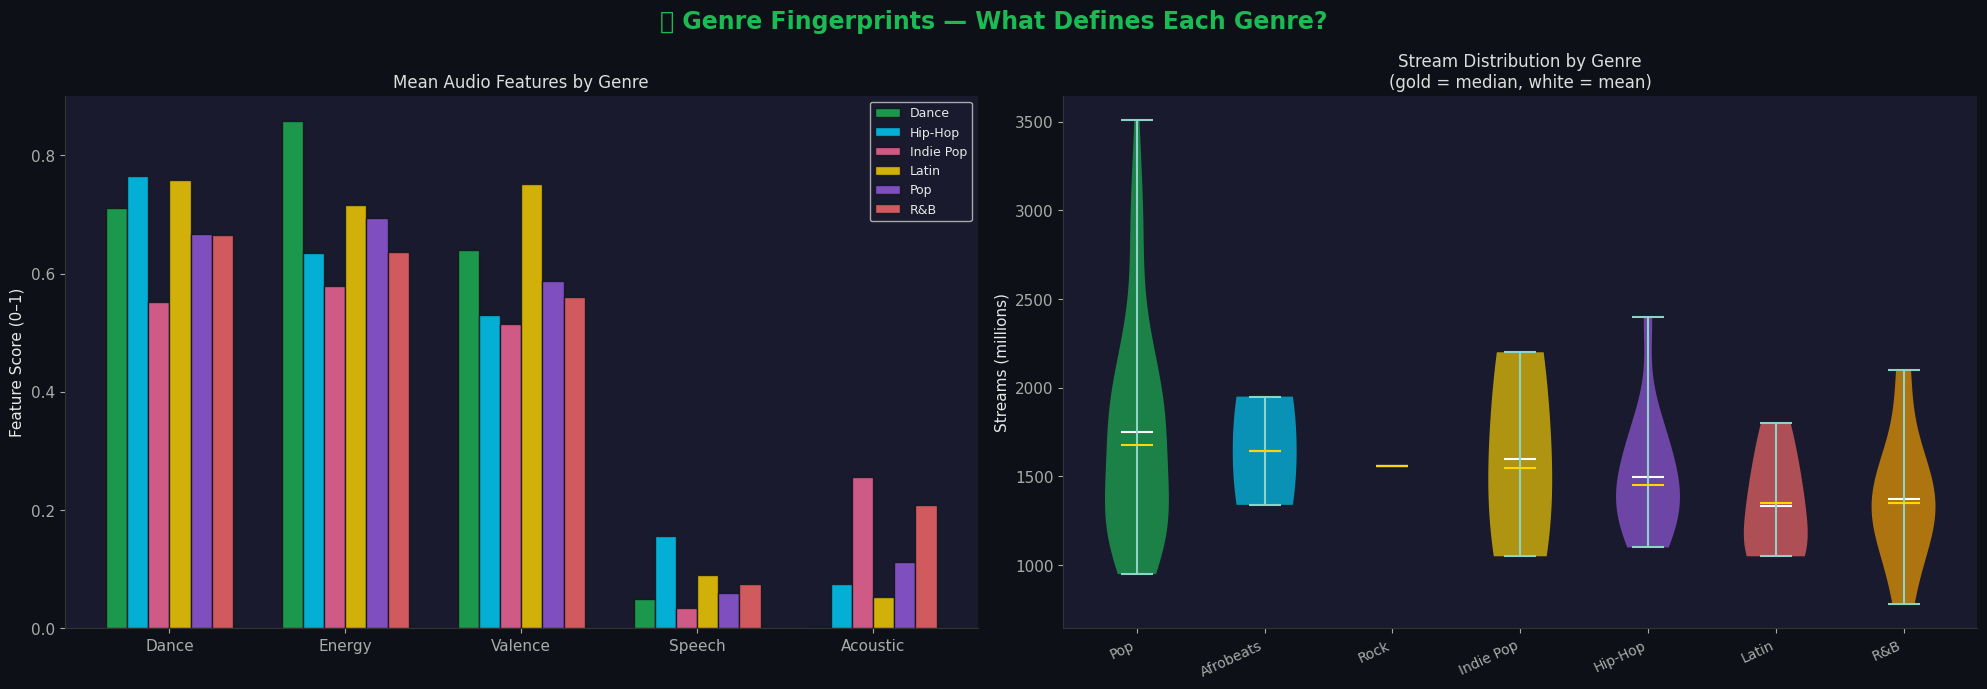

In [9]:
# ── 3.4 Genre Deep Dive ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle('🎸 Genre Fingerprints — What Defines Each Genre?',
             fontsize=17, fontweight='bold', color=C['green'])

# Radar chart data per genre
top_genres = df['genre'].value_counts().head(6).index.tolist()
radar_features = ['danceability','energy','valence','speechiness','acousticness']
radar_labels   = ['Dance','Energy','Valence','Speech','Acoustic']

# Bar chart — mean audio features by genre
genre_means = df.groupby('genre')[radar_features].mean()
genre_means_top = genre_means.loc[genre_means.index.isin(top_genres)]

x = np.arange(len(radar_features))
width = 0.12
for idx, (genre, row) in enumerate(genre_means_top.iterrows()):
    axes[0].bar(x + idx*width, row.values, width,
                label=genre, color=C['genre'][idx], alpha=0.8, edgecolor='#0d1117')

axes[0].set_xticks(x + width*(len(top_genres)-1)/2)
axes[0].set_xticklabels(radar_labels)
axes[0].set_ylabel('Feature Score (0–1)')
axes[0].set_title('Mean Audio Features by Genre', color='#ddd', fontsize=12)
axes[0].legend(fontsize=9, loc='upper right')

# Streams by genre (violin)
genre_order = df.groupby('genre')['streams_millions'].median().sort_values(ascending=False).index[:7]
data_violin = [df[df['genre']==g]['streams_millions'].values for g in genre_order]
parts = axes[1].violinplot(data_violin, positions=range(len(genre_order)),
                            showmedians=True, showmeans=True)
for pc, col in zip(parts['bodies'], C['genre']):
    pc.set_facecolor(col); pc.set_alpha(0.65)
parts['cmedians'].set_colors('#FFD700')
parts['cmeans'].set_colors('#fff')
axes[1].set_xticks(range(len(genre_order)))
axes[1].set_xticklabels(genre_order, rotation=25, ha='right', fontsize=10)
axes[1].set_ylabel('Streams (millions)')
axes[1].set_title('Stream Distribution by Genre\n(gold = median, white = mean)', color='#ddd', fontsize=12)

plt.tight_layout()
plt.savefig('genre_analysis.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

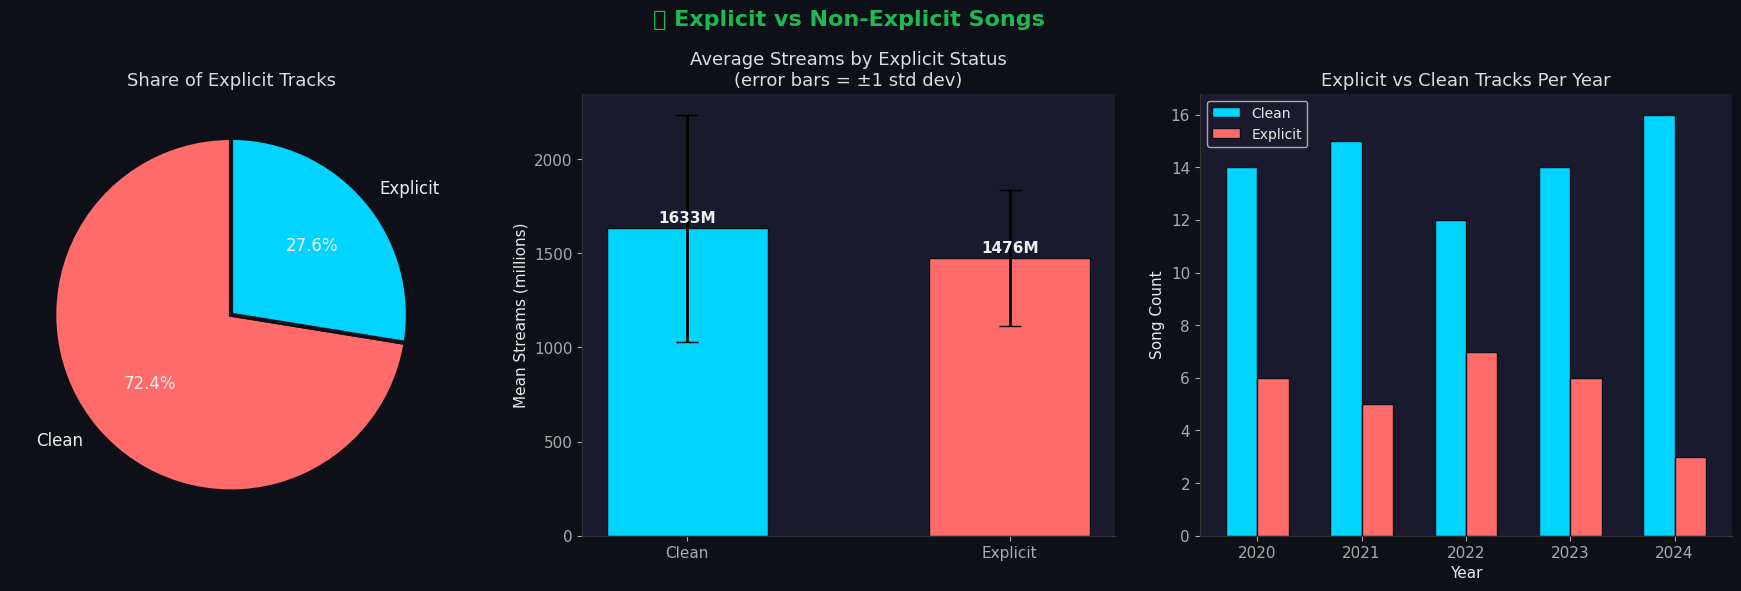

In [10]:
# ── 3.5 Explicit vs Non-Explicit ──────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('🔞 Explicit vs Non-Explicit Songs', fontsize=16,
             fontweight='bold', color=C['green'])

# Count pie
exp_counts = df['explicit'].map({1:'Explicit',0:'Clean'}).value_counts()
axes[0].pie(exp_counts.values, labels=exp_counts.index,
            colors=[C['coral'], C['blue']], autopct='%1.1f%%',
            startangle=90, wedgeprops={'edgecolor':'#0d1117','linewidth':3},
            textprops={'color':'#eee','fontsize':12})
axes[0].set_title('Share of Explicit Tracks', color='#ddd')

# Streams comparison
exp_streams = df.groupby('explicit')['streams_millions'].agg(['mean','median','std'])
exp_streams.index = ['Clean','Explicit']
bars = axes[1].bar(exp_streams.index, exp_streams['mean'],
                   color=[C['blue'], C['coral']], width=0.5, edgecolor='#0d1117',
                   yerr=exp_streams['std'], capsize=8, error_kw={'color':'white','lw':2})
for bar in bars:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
                 f"{bar.get_height():.0f}M", ha='center', color='#eee', fontweight='bold', fontsize=11)
axes[1].set_ylabel('Mean Streams (millions)')
axes[1].set_title('Average Streams by Explicit Status\n(error bars = ±1 std dev)', color='#ddd')

# Year trend
yearly_exp = df.groupby(['year','explicit']).size().unstack(fill_value=0)
yearly_exp.columns = ['Clean','Explicit']
yearly_exp.plot(kind='bar', ax=axes[2], color=[C['blue'], C['coral']],
                width=0.6, edgecolor='#0d1117')
axes[2].set_title('Explicit vs Clean Tracks Per Year', color='#ddd')
axes[2].set_xlabel('Year'); axes[2].set_ylabel('Song Count')
axes[2].legend(fontsize=10); axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('explicit_analysis.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
# 🔗 PART 4 — Correlation Analysis

<div style="background:#1a1a2e; padding:15px 20px; border-radius:10px; border-left:5px solid #00D4FF;">

**Correlation** measures the strength and direction of the relationship between two variables.

- **r = +1.0** → Perfect positive relationship (as X increases, Y increases)
- **r = 0.0** → No linear relationship
- **r = -1.0** → Perfect negative relationship (as X increases, Y decreases)

> ⚠️ **Correlation ≠ Causation.** Just because two things move together doesn't mean one causes the other.

</div>

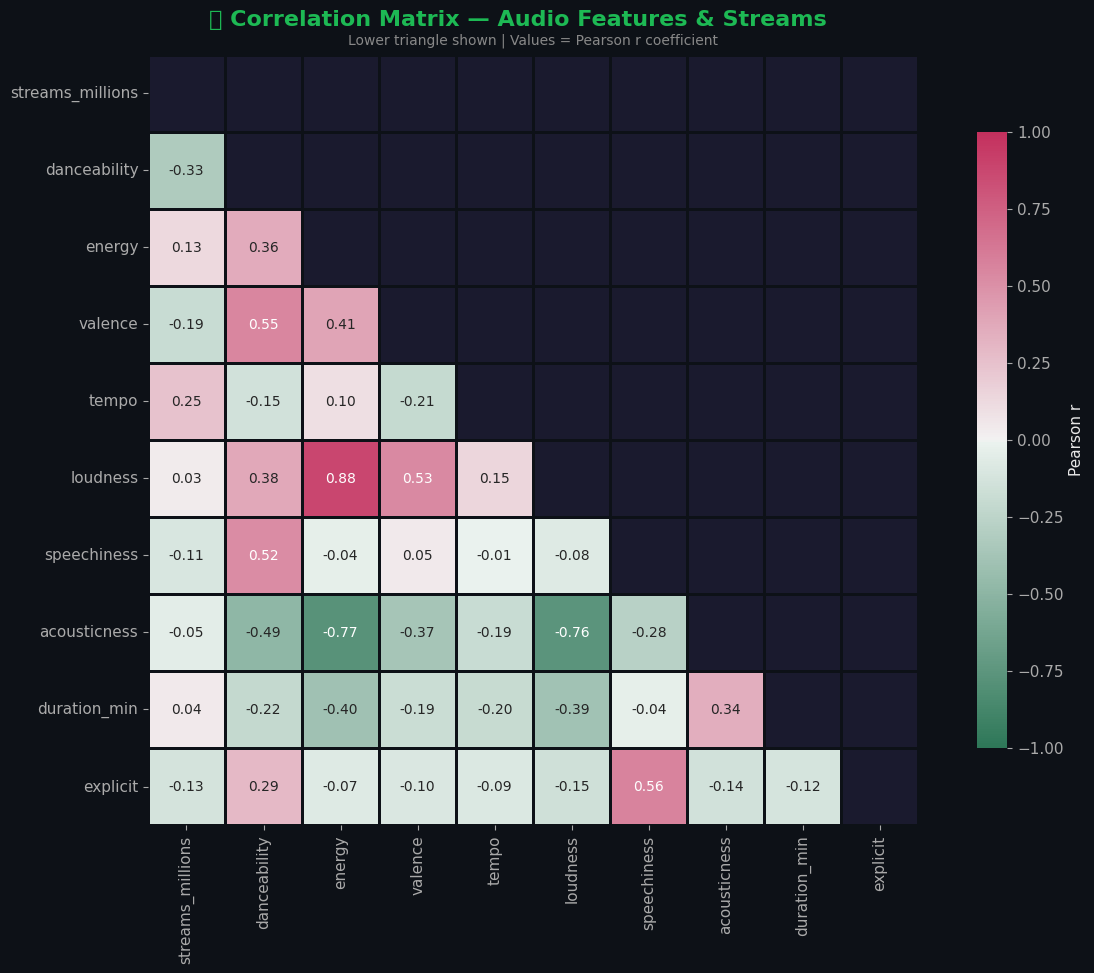

In [11]:
# ── 4.1 Correlation Heatmap ───────────────────────────────────────────
numeric_cols = ['streams_millions','danceability','energy','valence','tempo',
                'loudness','speechiness','acousticness','duration_min','explicit']

corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
fig.suptitle('🔗 Correlation Matrix — Audio Features & Streams',
             fontsize=16, fontweight='bold', color=C['green'], y=0.97)

# Custom diverging colormap (Spotify green ↔ neutral ↔ coral)
cmap = sns.diverging_palette(150, 0, s=80, l=45, as_cmap=True)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size':10},
            square=True, linewidths=0.8, linecolor='#0d1117',
            cbar_kws={'shrink':0.8, 'label':'Pearson r'}, ax=ax)

ax.set_title('Lower triangle shown | Values = Pearson r coefficient',
             color='#888', fontsize=10, pad=8)

plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

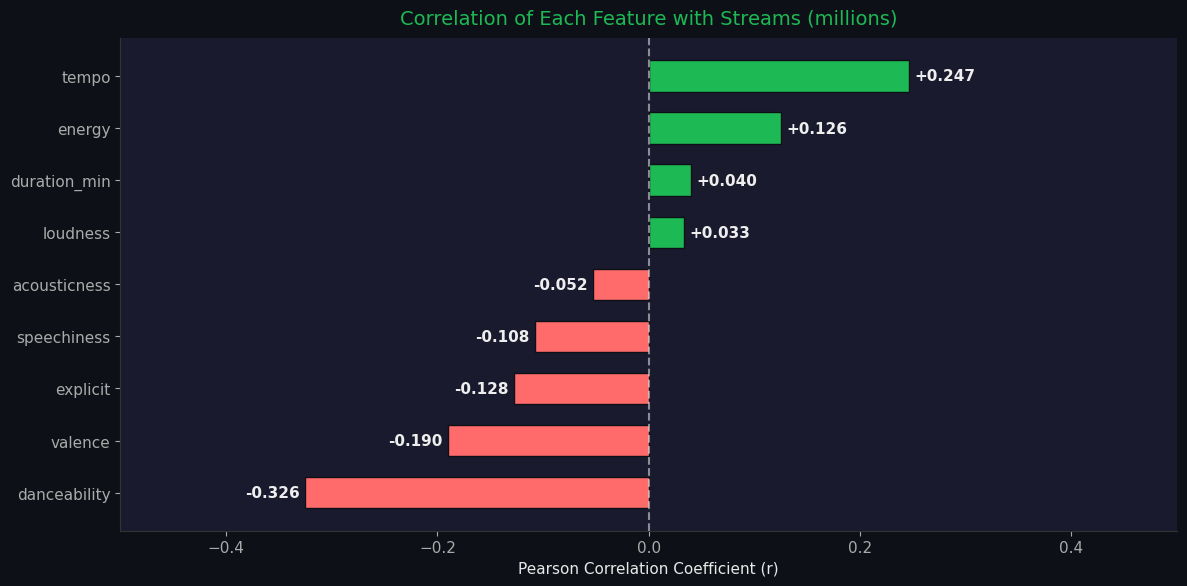


📊 TOP CORRELATIONS WITH STREAMS:
  danceability         r=-0.326  (strong negative)
  tempo                r=+0.247  (moderate positive)
  valence              r=-0.190  (moderate negative)
  explicit             r=-0.128  (weak negative)
  energy               r=+0.126  (weak positive)
  speechiness          r=-0.108  (weak negative)
  acousticness         r=-0.052  (weak negative)
  duration_min         r=+0.040  (weak positive)
  loudness             r=+0.033  (weak positive)


In [12]:
# ── 4.2 Correlations with Streams (ranked) ───────────────────────────
stream_corr = df[numeric_cols].corr()['streams_millions'].drop('streams_millions').sort_values()

fig, ax = plt.subplots(figsize=(12, 6))
colors_bar = [C['coral'] if v < 0 else C['green'] for v in stream_corr.values]
bars = ax.barh(stream_corr.index, stream_corr.values, color=colors_bar,
               height=0.6, edgecolor='#0d1117', linewidth=1)
ax.axvline(0, color='white', lw=1.5, ls='--', alpha=0.5)

for bar, val in zip(bars, stream_corr.values):
    xpos = val + 0.005 if val >= 0 else val - 0.005
    ha = 'left' if val >= 0 else 'right'
    ax.text(xpos, bar.get_y() + bar.get_height()/2, f'{val:+.3f}',
            va='center', ha=ha, color='#eee', fontsize=11, fontweight='bold')

ax.set_title('Correlation of Each Feature with Streams (millions)',
             color=C['green'], fontsize=14, pad=10)
ax.set_xlabel('Pearson Correlation Coefficient (r)')
ax.set_xlim(-0.5, 0.5)

plt.tight_layout()
plt.savefig('stream_correlations.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

print("\n📊 TOP CORRELATIONS WITH STREAMS:")
for feat, val in stream_corr.abs().sort_values(ascending=False).items():
    direction = "positive" if stream_corr[feat] > 0 else "negative"
    strength = "strong" if val > 0.3 else "moderate" if val > 0.15 else "weak"
    print(f"  {feat:<20} r={stream_corr[feat]:+.3f}  ({strength} {direction})")

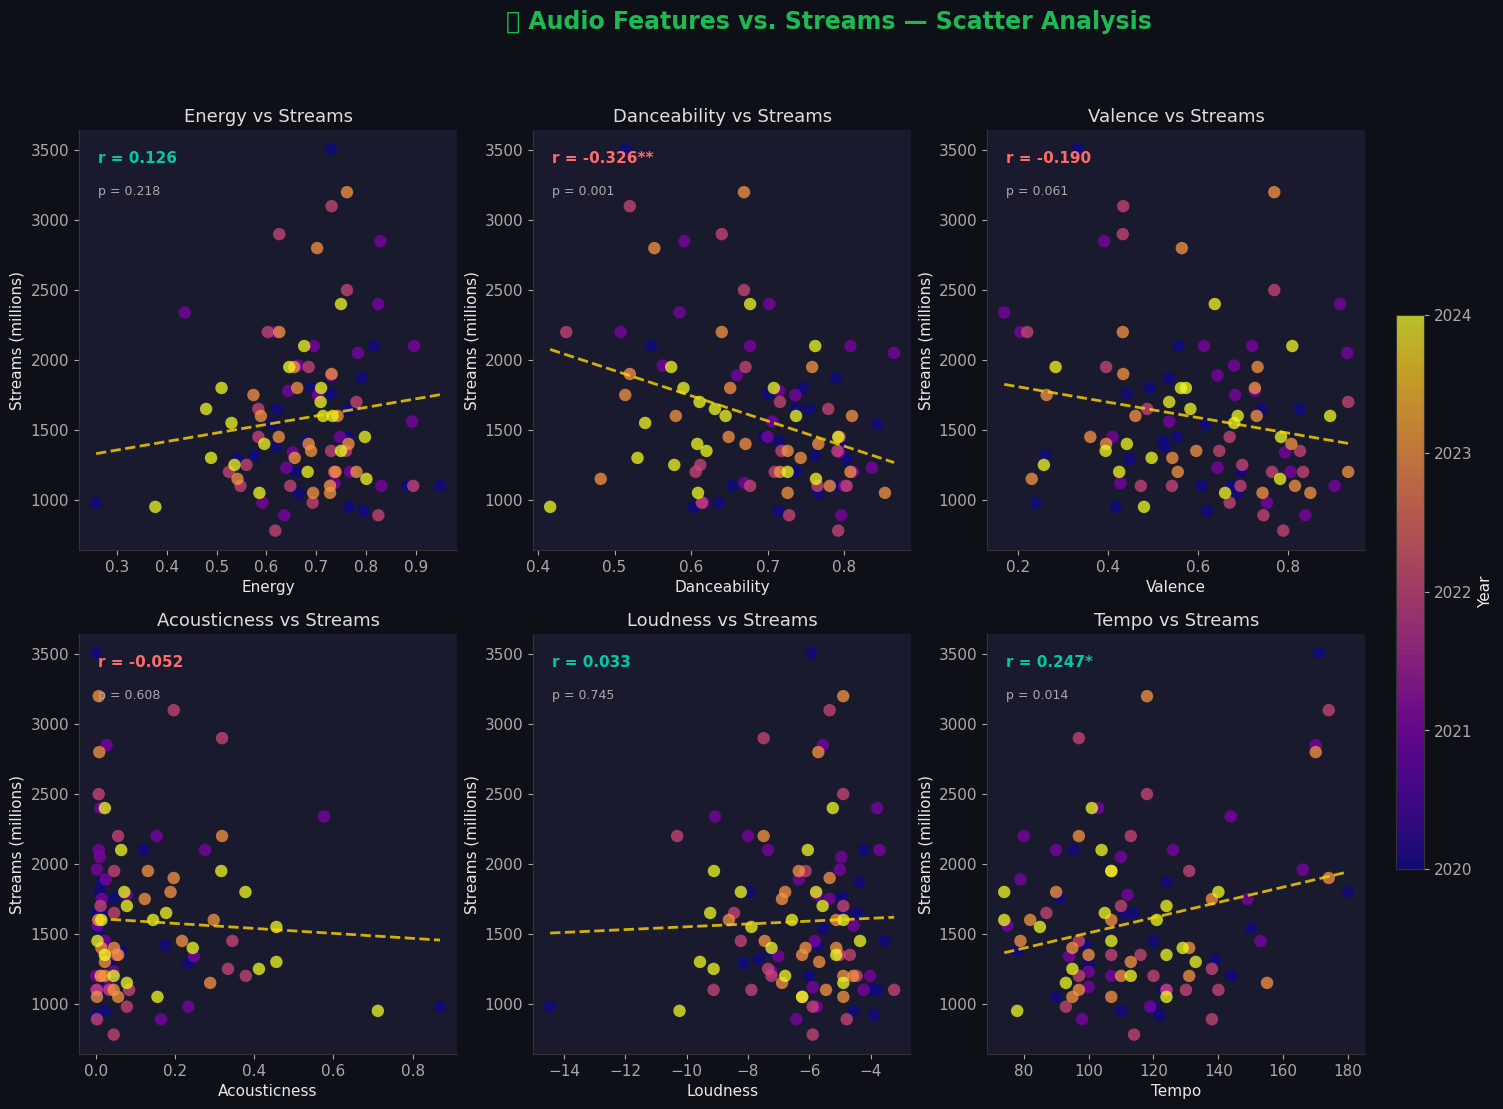

** p<0.01  * p<0.05  (no asterisk = not statistically significant)


In [13]:
# ── 4.3 Scatter Plots — Top Correlated Features vs Streams ──────────
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('🔍 Audio Features vs. Streams — Scatter Analysis',
             fontsize=17, fontweight='bold', color=C['green'])

scatter_features = ['energy','danceability','valence','acousticness','loudness','tempo']

for i, feat in enumerate(scatter_features):
    ax = axes[i//3][i%3]
    scatter = ax.scatter(df[feat], df['streams_millions'],
                         c=df['year'].astype(float), cmap='plasma',
                         alpha=0.75, s=80, edgecolors='none')
    
    # Linear regression line
    x_clean = df[feat].dropna()
    y_clean = df.loc[x_clean.index, 'streams_millions']
    m, b, r, p, se = stats.linregress(x_clean, y_clean)
    x_line = np.linspace(x_clean.min(), x_clean.max(), 100)
    ax.plot(x_line, m*x_line + b, color=C['gold'], lw=2, ls='--', alpha=0.8)
    
    # Annotate r value
    sig = "**" if p < 0.01 else "*" if p < 0.05 else ""
    color_r = C['mint'] if r > 0 else C['coral']
    ax.text(0.05, 0.95, f'r = {r:.3f}{sig}', transform=ax.transAxes,
            color=color_r, fontsize=11, fontweight='bold', va='top')
    ax.text(0.05, 0.87, f'p = {p:.3f}', transform=ax.transAxes,
            color='#aaa', fontsize=9, va='top')
    
    ax.set_xlabel(feat.replace('_',' ').title())
    ax.set_ylabel('Streams (millions)')
    ax.set_title(f'{feat.replace("_"," ").title()} vs Streams', color='#ddd')

# Colorbar for year
cbar = plt.colorbar(scatter, ax=axes, shrink=0.6, pad=0.02)
cbar.set_label('Year', color='#eee')
cbar.set_ticks([2020,2021,2022,2023,2024])

plt.savefig('scatter_analysis.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("** p<0.01  * p<0.05  (no asterisk = not statistically significant)")

---
# ⚙️ PART 5 — Feature Engineering

✅ Features engineered!
   Base features:     10
   Genre dummies:     9

🎯 Target variable: 'log_streams' (log-transformed streams)
   Original range:  780M – 3,510M
   Log range:        6.66 – 8.16


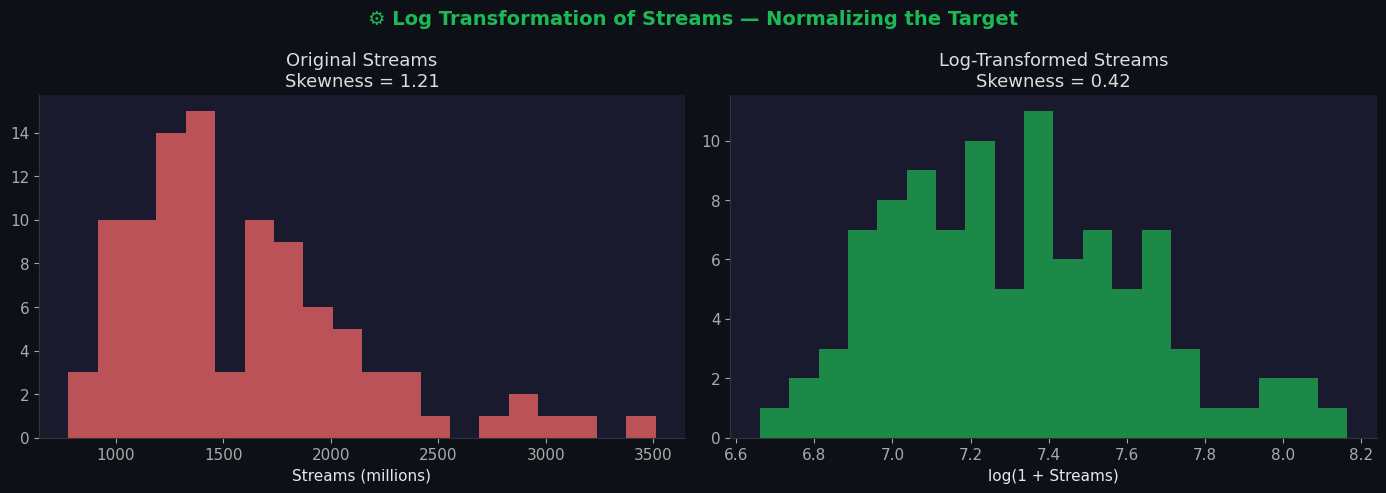

In [14]:
# ── 5.1 Prepare Features for Regression ──────────────────────────────
df_model = df.copy()

# Feature 1: log-transform streams (right-skewed)
df_model['log_streams'] = np.log1p(df_model['streams_millions'])

# Feature 2: loudness is negative — take absolute value
df_model['loudness_abs'] = df_model['loudness'].abs()

# Feature 3: energy * danceability interaction
df_model['energy_dance'] = df_model['energy'] * df_model['danceability']

# Feature 4: year as ordinal (trend variable)
df_model['year_ord'] = df_model['year'] - 2020

# Feature 5: genre dummies
genre_dummies = pd.get_dummies(df_model['genre'], prefix='genre', drop_first=True)
df_model = pd.concat([df_model, genre_dummies], axis=1)

feature_cols = ['danceability','energy','valence','tempo','loudness_abs',
                'speechiness','acousticness','explicit','year_ord','energy_dance']

print("✅ Features engineered!")
print(f"   Base features:     {len(feature_cols)}")
print(f"   Genre dummies:     {len(genre_dummies.columns)}")
print(f"\n🎯 Target variable: 'log_streams' (log-transformed streams)")
print(f"   Original range:  {df['streams_millions'].min():,}M – {df['streams_millions'].max():,}M")
print(f"   Log range:        {df_model['log_streams'].min():.2f} – {df_model['log_streams'].max():.2f}")

# Compare distributions before/after log transform
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('⚙️ Log Transformation of Streams — Normalizing the Target',
             fontsize=14, fontweight='bold', color=C['green'])

axes[0].hist(df_model['streams_millions'], bins=20, color=C['coral'], alpha=0.7, edgecolor='none')
axes[0].set_title(f'Original Streams\nSkewness = {skew(df_model.streams_millions):.2f}', color='#ddd')
axes[0].set_xlabel('Streams (millions)')

axes[1].hist(df_model['log_streams'], bins=20, color=C['green'], alpha=0.7, edgecolor='none')
axes[1].set_title(f'Log-Transformed Streams\nSkewness = {skew(df_model.log_streams):.2f}', color='#ddd')
axes[1].set_xlabel('log(1 + Streams)')

plt.tight_layout()
plt.savefig('log_transform.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
# 📐 PART 6 — Simple Linear Regression

<div style="background:#1a1a2e; padding:18px 22px; border-radius:10px; border-left:5px solid #FFD700;">

## The Math Behind Simple Linear Regression

We model the relationship: **y = β₀ + β₁x + ε**

| Symbol | Meaning |
|--------|---------|
| **y** | Target (log-streams) |
| **x** | One predictor (e.g. danceability) |
| **β₀** | Intercept (y when x = 0) |
| **β₁** | Slope (change in y per unit x) |
| **ε** | Error / residual (what the model can't explain) |

The **OLS method** finds β values that minimize the **sum of squared residuals (SSR)**:
$$SSR = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

</div>

In [15]:
# ── 6.1 Simple Regression: Energy → Streams ──────────────────────────
X_simple = df_model['energy'].values.reshape(-1, 1)
y_target  = df_model['log_streams'].values

X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y_target, test_size=0.2, random_state=42)

slr = LinearRegression()
slr.fit(X_train, y_train)
y_pred_test = slr.predict(X_test)

print("═"*55)
print("  SIMPLE LINEAR REGRESSION RESULTS")
print("  Predictor: Energy    Target: log(Streams)")
print("═"*55)
print(f"  Intercept (β₀):  {slr.intercept_:.4f}")
print(f"  Slope (β₁):      {slr.coef_[0]:.4f}")
print(f"  Equation:        log_streams = {slr.intercept_:.3f} + {slr.coef_[0]:.3f} × energy")
print()
print(f"  Train R²:  {slr.score(X_train, y_train):.4f}")
print(f"  Test  R²:  {slr.score(X_test, y_test):.4f}")
print(f"  Test  MAE: {mean_absolute_error(y_test, y_pred_test):.4f}")
print(f"  Test  RMSE:{np.sqrt(mean_squared_error(y_test, y_pred_test)):.4f}")
print()
print(f"  Interpretation: A 0.1 increase in energy is associated with")
print(f"  a {slr.coef_[0]*0.1:.3f} increase in log-streams, i.e. a ~{(np.exp(slr.coef_[0]*0.1)-1)*100:.1f}% more streams")

═══════════════════════════════════════════════════════
  SIMPLE LINEAR REGRESSION RESULTS
  Predictor: Energy    Target: log(Streams)
═══════════════════════════════════════════════════════
  Intercept (β₀):  7.0985
  Slope (β₁):      0.2837
  Equation:        log_streams = 7.099 + 0.284 × energy

  Train R²:  0.0125
  Test  R²:  -0.1497
  Test  MAE: 0.2819
  Test  RMSE:0.3495

  Interpretation: A 0.1 increase in energy is associated with
  a 0.028 increase in log-streams, i.e. a ~2.9% more streams


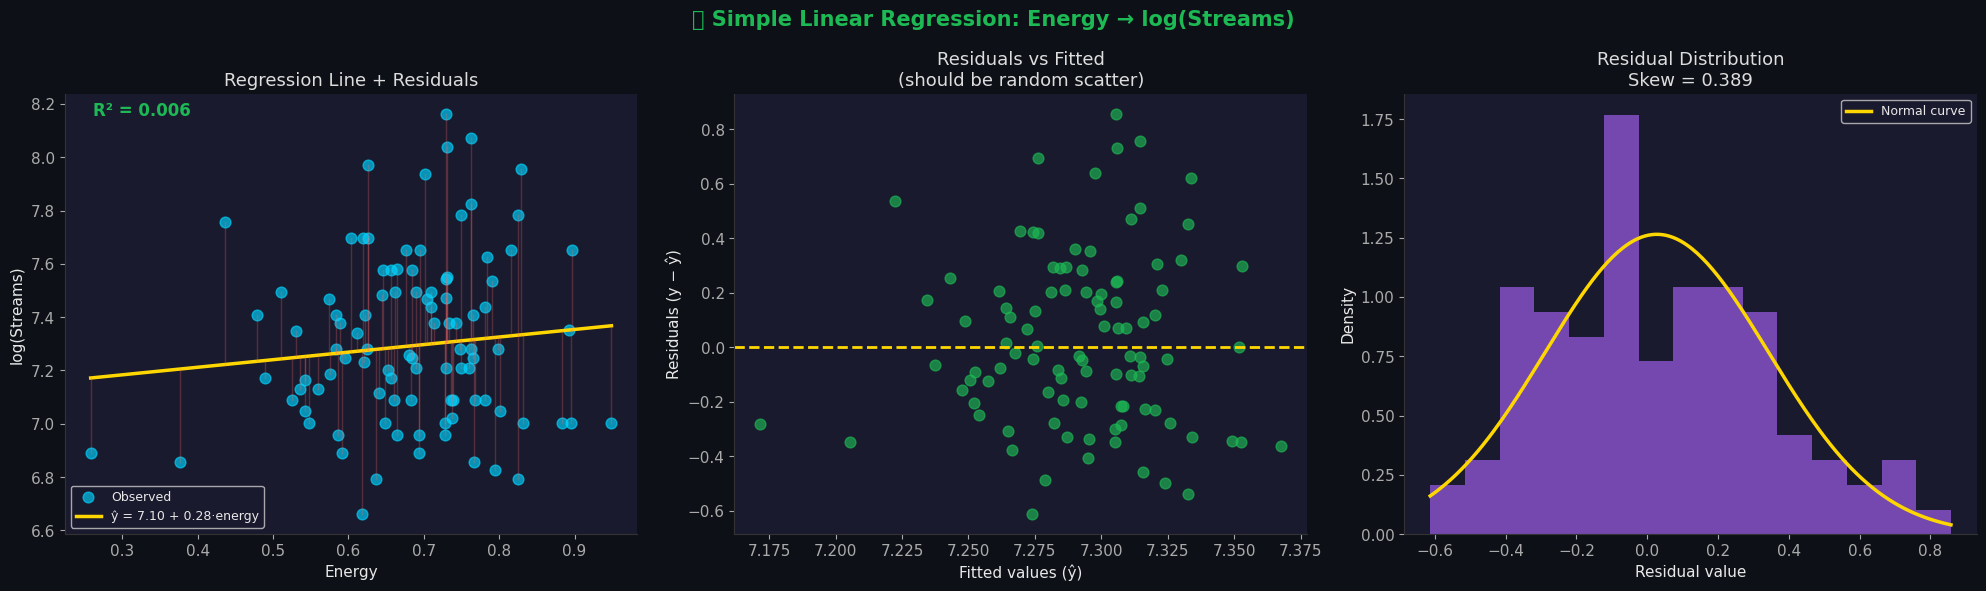

In [16]:
# ── 6.2 Visual: Regression Line & Residuals ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('📐 Simple Linear Regression: Energy → log(Streams)',
             fontsize=15, fontweight='bold', color=C['green'])

X_all  = df_model['energy'].values
y_all  = df_model['log_streams'].values
y_hat  = slr.predict(X_all.reshape(-1,1))
resids = y_all - y_hat

# (a) Scatter + regression line
axes[0].scatter(X_all, y_all, color=C['blue'], alpha=0.65, s=60, label='Observed')
x_line = np.linspace(X_all.min(), X_all.max(), 200)
axes[0].plot(x_line, slr.predict(x_line.reshape(-1,1)),
             color=C['gold'], lw=2.5, label=f'ŷ = {slr.intercept_:.2f} + {slr.coef_[0]:.2f}·energy')
for xi, yi, yhi in zip(X_all, y_all, y_hat):
    axes[0].plot([xi, xi], [yi, yhi], color=C['coral'], alpha=0.25, lw=1)
axes[0].set_xlabel('Energy'); axes[0].set_ylabel('log(Streams)')
axes[0].set_title('Regression Line + Residuals', color='#ddd')
axes[0].legend(fontsize=9)
axes[0].text(0.05, 0.95, f'R² = {slr.score(X_all.reshape(-1,1), y_all):.3f}',
             transform=axes[0].transAxes, color=C['green'], fontsize=12, fontweight='bold')

# (b) Residuals vs fitted
axes[1].scatter(y_hat, resids, color=C['green'], alpha=0.65, s=60)
axes[1].axhline(0, color=C['gold'], lw=2, ls='--')
axes[1].set_xlabel('Fitted values (ŷ)'); axes[1].set_ylabel('Residuals (y − ŷ)')
axes[1].set_title('Residuals vs Fitted\n(should be random scatter)', color='#ddd')

# (c) Residual histogram + Q-Q suggestion
axes[2].hist(resids, bins=15, color=C['purple'], alpha=0.7, edgecolor='none', density=True)
x_norm = np.linspace(resids.min(), resids.max(), 200)
axes[2].plot(x_norm, stats.norm.pdf(x_norm, resids.mean(), resids.std()),
             color=C['gold'], lw=2.5, label='Normal curve')
axes[2].set_xlabel('Residual value'); axes[2].set_ylabel('Density')
axes[2].set_title(f'Residual Distribution\nSkew = {skew(resids):.3f}', color='#ddd')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig('simple_regression.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
# 🤖 PART 7 — Multiple Linear Regression

In [17]:
# ── 7.1 Build the Multiple Regression Model ──────────────────────────
feature_cols_final = ['danceability','energy','valence','tempo','loudness_abs',
                      'speechiness','acousticness','explicit','year_ord','energy_dance']

X = df_model[feature_cols_final].values
y = df_model['log_streams'].values

# Standardize features for comparability
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred  = mlr.predict(X_test)
y_train_pred = mlr.predict(X_train)

print("═"*60)
print("  MULTIPLE LINEAR REGRESSION RESULTS")
print("  Target: log(Streams)    Features:", len(feature_cols_final))
print("═"*60)
print(f"  Train R²:     {mlr.score(X_train, y_train):.4f}  ({mlr.score(X_train, y_train)*100:.1f}% variance explained)")
print(f"  Test  R²:     {mlr.score(X_test,  y_test):.4f}  ({mlr.score(X_test, y_test)*100:.1f}% variance explained)")
print(f"  Train MAE:    {mean_absolute_error(y_train, y_train_pred):.4f}")
print(f"  Test  MAE:    {mean_absolute_error(y_test, y_pred):.4f}")
print(f"  Test  RMSE:   {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print()
print("  FEATURE COEFFICIENTS (standardized — larger |value| = more important):")
print("  " + "-"*52)
coef_df = pd.DataFrame({'Feature': feature_cols_final, 'Coefficient': mlr.coef_})
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)
for _, row in coef_df.iterrows():
    bar = "█" * int(abs(row['Coefficient']) * 30)
    sign = "+" if row['Coefficient'] > 0 else "-"
    print(f"  {row['Feature']:<20} {sign}{abs(row['Coefficient']):.4f}  {bar}")

════════════════════════════════════════════════════════════
  MULTIPLE LINEAR REGRESSION RESULTS
  Target: log(Streams)    Features: 10
════════════════════════════════════════════════════════════
  Train R²:     0.1375  (13.7% variance explained)
  Test  R²:     0.3516  (35.2% variance explained)
  Train MAE:    0.2372
  Test  MAE:    0.2105
  Test  RMSE:   0.2625

  FEATURE COEFFICIENTS (standardized — larger |value| = more important):
  ----------------------------------------------------
  energy_dance         -0.6928  ████████████████████
  energy               +0.5960  █████████████████
  danceability         +0.3149  █████████
  loudness_abs         +0.0696  ██
  explicit             -0.0396  █
  acousticness         +0.0364  █
  speechiness          +0.0343  █
  year_ord             +0.0316  
  tempo                +0.0194  
  valence              +0.0019  


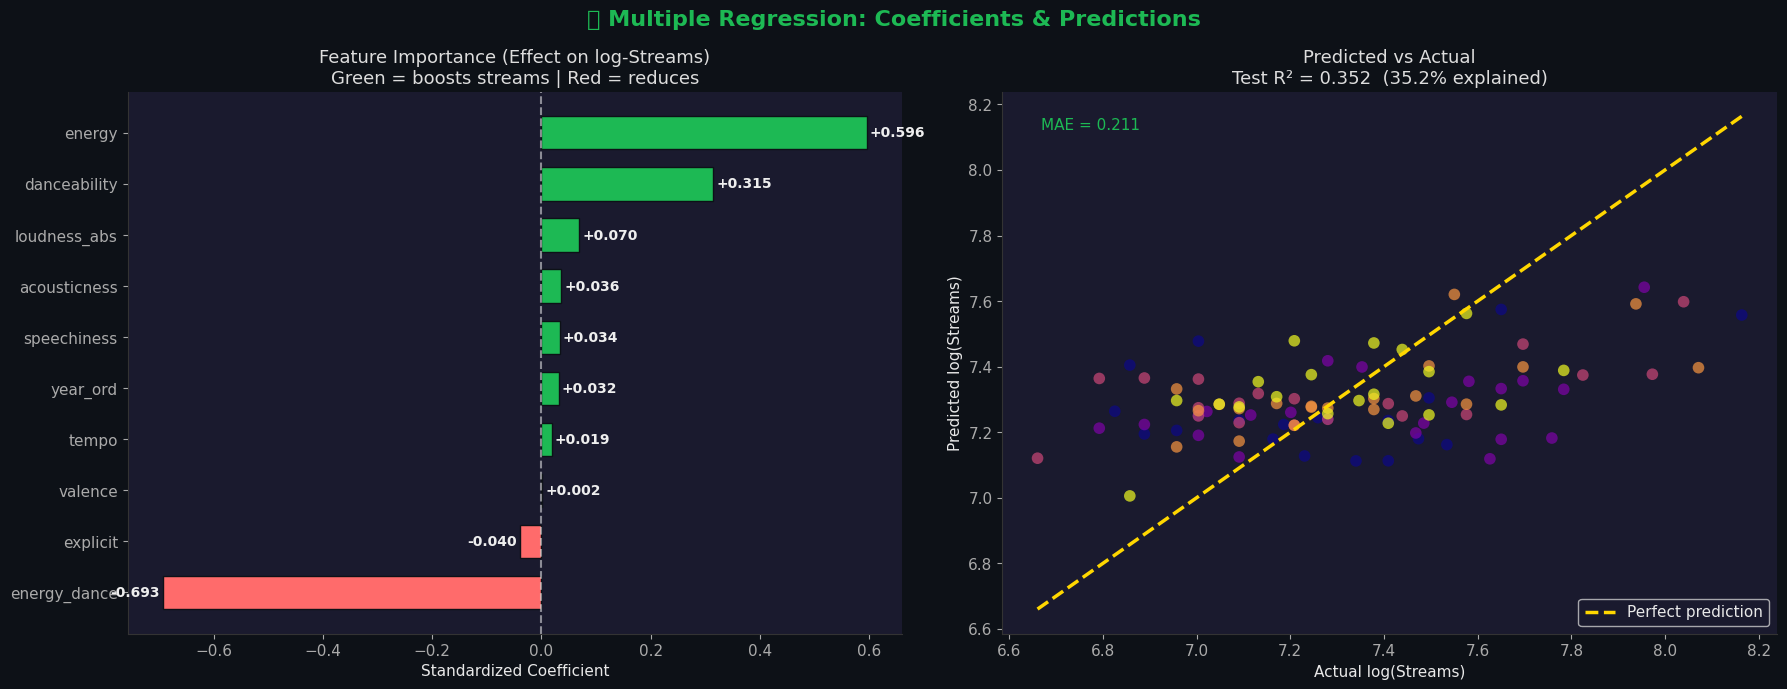

In [18]:
# ── 7.2 Coefficient Plot & Predicted vs Actual ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('🤖 Multiple Regression: Coefficients & Predictions',
             fontsize=16, fontweight='bold', color=C['green'])

# Coefficient importance plot
coef_sorted = coef_df.sort_values('Coefficient')
colors_coef = [C['coral'] if c < 0 else C['green'] for c in coef_sorted['Coefficient']]
bars = axes[0].barh(coef_sorted['Feature'], coef_sorted['Coefficient'],
                    color=colors_coef, height=0.65, edgecolor='#0d1117')
axes[0].axvline(0, color='white', lw=1.5, ls='--', alpha=0.5)
for bar, val in zip(bars, coef_sorted['Coefficient']):
    xpos = val + 0.005 if val >= 0 else val - 0.005
    axes[0].text(xpos, bar.get_y() + bar.get_height()/2,
                 f'{val:+.3f}', va='center', ha='left' if val >= 0 else 'right',
                 color='#eee', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Standardized Coefficient')
axes[0].set_title('Feature Importance (Effect on log-Streams)\nGreen = boosts streams | Red = reduces', color='#ddd')

# Predicted vs Actual (test set)
y_all_pred = mlr.predict(X_scaled)
axes[1].scatter(y, y_all_pred, c=df_model['year'].astype(float),
                cmap='plasma', alpha=0.7, s=70, edgecolors='none')
perfect_line = [y.min(), y.max()]
axes[1].plot(perfect_line, perfect_line, color=C['gold'], lw=2.5, ls='--', label='Perfect prediction')
test_r2 = mlr.score(X_test, y_test)
axes[1].set_xlabel('Actual log(Streams)')
axes[1].set_ylabel('Predicted log(Streams)')
axes[1].set_title(f'Predicted vs Actual\nTest R² = {test_r2:.3f}  ({test_r2*100:.1f}% explained)', color='#ddd')
axes[1].legend()
axes[1].text(0.05, 0.93, f'MAE = {mean_absolute_error(y_test, y_pred):.3f}',
             transform=axes[1].transAxes, color=C['green'], fontsize=11)

plt.tight_layout()
plt.savefig('multiple_regression.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

---
# 🔬 PART 8 — Regression Diagnostics

<div style="background:#1a1a2e; padding:15px 20px; border-radius:10px; border-left:5px solid #9B5DE5;">

## The 4 Key OLS Assumptions

A valid regression model requires:

1. **Linearity** — The relationship between X and y is linear
2. **Independence** — Residuals are independent of each other
3. **Homoscedasticity** — Residuals have constant variance (no fan shape)
4. **Normality** — Residuals are approximately normally distributed

</div>

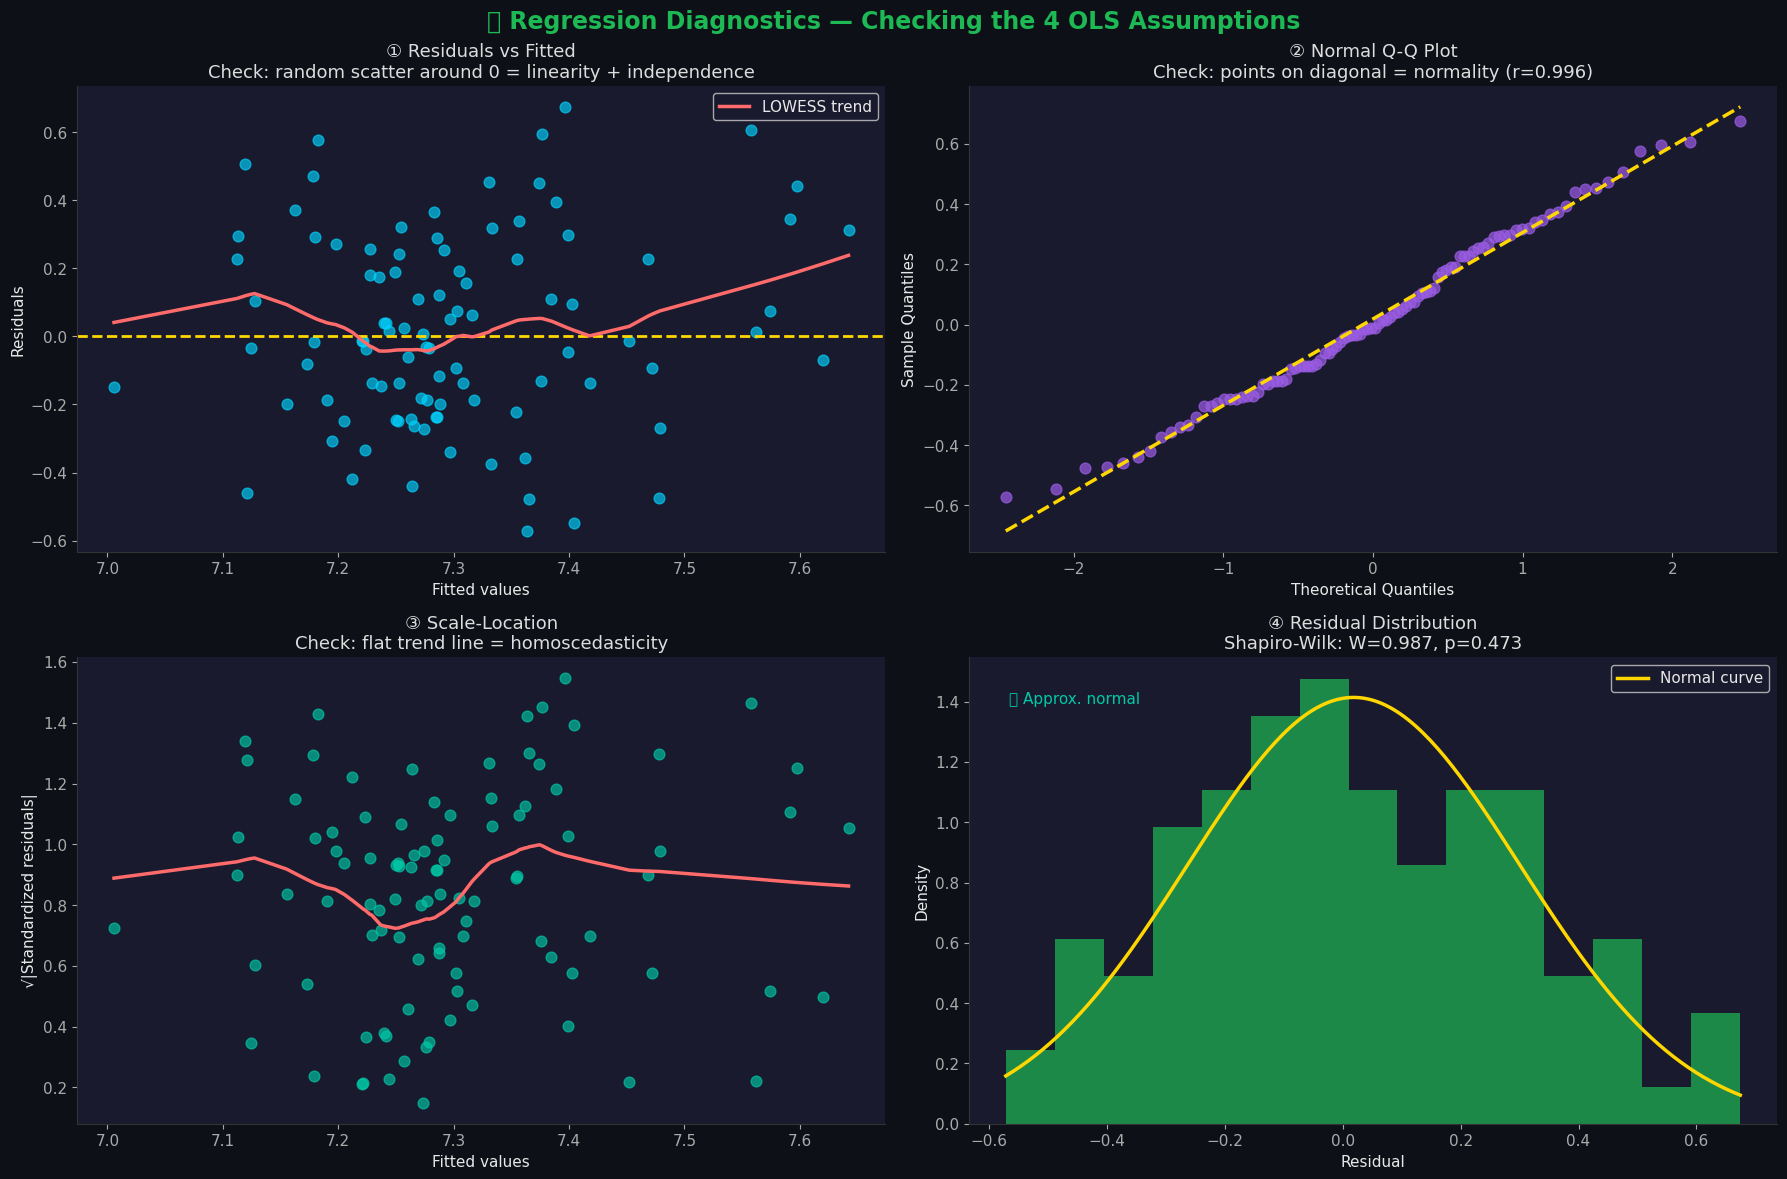

In [19]:
# ── 8.1 Four Residual Diagnostic Plots ────────────────────────────────
y_all_pred = mlr.predict(X_scaled)
residuals  = y - y_all_pred
std_resid  = residuals / residuals.std()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('🔬 Regression Diagnostics — Checking the 4 OLS Assumptions',
             fontsize=17, fontweight='bold', color=C['green'])

# (1) Residuals vs Fitted
axes[0,0].scatter(y_all_pred, residuals, color=C['blue'], alpha=0.65, s=60)
axes[0,0].axhline(0, color=C['gold'], lw=2, ls='--')
lowess = sm.nonparametric.lowess(residuals, y_all_pred, frac=0.5)
axes[0,0].plot(lowess[:,0], lowess[:,1], color=C['coral'], lw=2.5, label='LOWESS trend')
axes[0,0].set_xlabel('Fitted values'); axes[0,0].set_ylabel('Residuals')
axes[0,0].set_title('① Residuals vs Fitted\nCheck: random scatter around 0 = linearity + independence', color='#ddd')
axes[0,0].legend()

# (2) Q-Q Plot (normality)
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[0,1].scatter(osm, osr, color=C['purple'], alpha=0.7, s=60)
ql = np.linspace(min(osm), max(osm), 100)
axes[0,1].plot(ql, slope*ql + intercept, color=C['gold'], lw=2.5, ls='--')
axes[0,1].set_xlabel('Theoretical Quantiles'); axes[0,1].set_ylabel('Sample Quantiles')
axes[0,1].set_title(f'② Normal Q-Q Plot\nCheck: points on diagonal = normality (r={r:.3f})', color='#ddd')

# (3) Scale-Location (homoscedasticity)
axes[1,0].scatter(y_all_pred, np.sqrt(np.abs(std_resid)), color=C['mint'], alpha=0.65, s=60)
axes[1,0].set_xlabel('Fitted values'); axes[1,0].set_ylabel('√|Standardized residuals|')
axes[1,0].set_title('③ Scale-Location\nCheck: flat trend line = homoscedasticity', color='#ddd')
lowess2 = sm.nonparametric.lowess(np.sqrt(np.abs(std_resid)), y_all_pred, frac=0.5)
axes[1,0].plot(lowess2[:,0], lowess2[:,1], color=C['coral'], lw=2.5)

# (4) Residual histogram
axes[1,1].hist(residuals, bins=15, color=C['green'], alpha=0.7, edgecolor='none', density=True)
x_norm = np.linspace(residuals.min(), residuals.max(), 200)
axes[1,1].plot(x_norm, stats.norm.pdf(x_norm, residuals.mean(), residuals.std()),
               color=C['gold'], lw=2.5, label='Normal curve')
stat_sw, p_sw = shapiro(residuals)
axes[1,1].set_xlabel('Residual'); axes[1,1].set_ylabel('Density')
axes[1,1].set_title(f'④ Residual Distribution\nShapiro-Wilk: W={stat_sw:.3f}, p={p_sw:.3f}', color='#ddd')
axes[1,1].legend()
note = "✅ Approx. normal" if p_sw > 0.05 else "⚠️ Deviation from normality"
axes[1,1].text(0.05, 0.90, note, transform=axes[1,1].transAxes, color=C['mint'] if p_sw > 0.05 else C['coral'], fontsize=11)

plt.tight_layout()
plt.savefig('regression_diagnostics.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

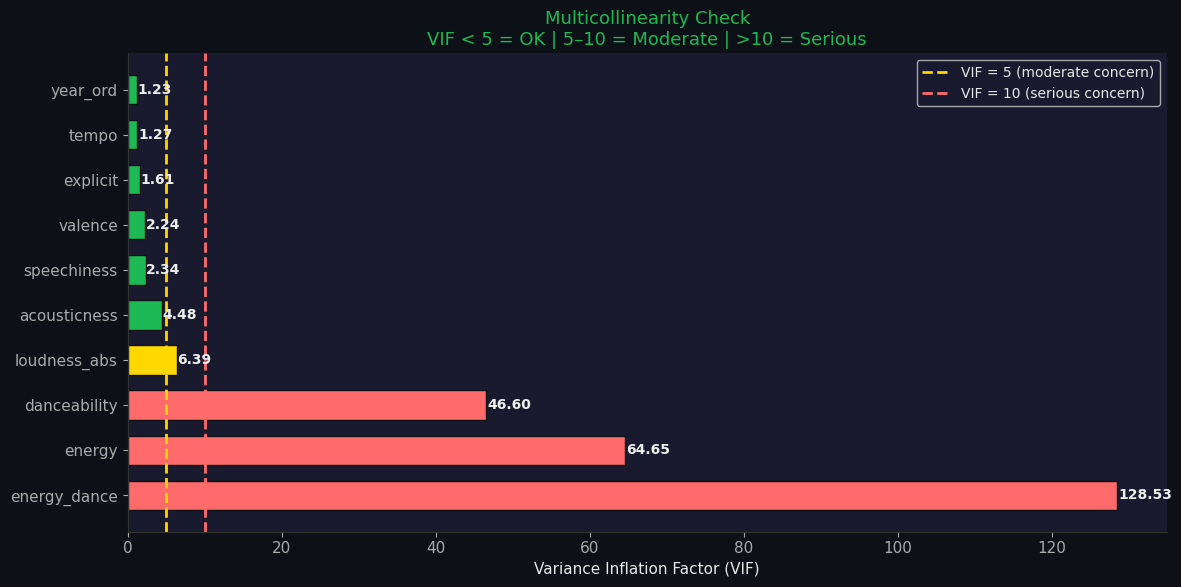


VIF SUMMARY:
  energy_dance           VIF = 128.53  ❌ High
  energy                 VIF = 64.65  ❌ High
  danceability           VIF = 46.60  ❌ High
  loudness_abs           VIF = 6.39  ⚠️ Moderate
  acousticness           VIF = 4.48  ✅ OK
  speechiness            VIF = 2.34  ✅ OK
  valence                VIF = 2.24  ✅ OK
  explicit               VIF = 1.61  ✅ OK
  tempo                  VIF = 1.27  ✅ OK
  year_ord               VIF = 1.23  ✅ OK


In [20]:
# ── 8.2 VIF — Multicollinearity Check ────────────────────────────────
X_df = pd.DataFrame(X_scaled, columns=feature_cols_final)
X_sm  = sm.add_constant(X_df)

vif_data = pd.DataFrame()
vif_data['Feature'] = feature_cols_final
vif_data['VIF'] = [variance_inflation_factor(X_sm.values, i+1)
                   for i in range(len(feature_cols_final))]
vif_data = vif_data.sort_values('VIF', ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
colors_vif = [C['coral'] if v > 10 else C['gold'] if v > 5 else C['green']
              for v in vif_data['VIF']]
bars = ax.barh(vif_data['Feature'], vif_data['VIF'],
               color=colors_vif, height=0.65, edgecolor='#0d1117')
ax.axvline(5,  color=C['gold'],  lw=2, ls='--', label='VIF = 5 (moderate concern)')
ax.axvline(10, color=C['coral'], lw=2, ls='--', label='VIF = 10 (serious concern)')
for bar, val in zip(bars, vif_data['VIF']):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', color='#eee', fontsize=10, fontweight='bold')
ax.set_xlabel('Variance Inflation Factor (VIF)')
ax.set_title('Multicollinearity Check\nVIF < 5 = OK | 5–10 = Moderate | >10 = Serious',
             color=C['green'], fontsize=13)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('vif_analysis.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()

print("\nVIF SUMMARY:")
for _, row in vif_data.iterrows():
    status = "✅ OK" if row['VIF'] < 5 else "⚠️ Moderate" if row['VIF'] < 10 else "❌ High"
    print(f"  {row['Feature']:<22} VIF = {row['VIF']:.2f}  {status}")

---
# 🎯 PART 9 — Conclusions

## What Did the Data Reveal?

### 🎵 On the Music Itself
> The **audio fingerprint of a hit song** is surprisingly consistent: high danceability (~0.69), high energy (~0.68), and moderate positive valence (~0.57). The biggest hits sit squarely in that "dancefloor-ready but emotionally resonant" sweet spot.

### 📈 On Trends (2020 → 2024)
> Music has gotten **more acoustic and emotionally complex** — raw energy metrics dipped slightly while acousticness rose, reflecting the rise of artists like Olivia Rodrigo, Hozier, and Chappell Roan who blend pop production with organic instrumentation.

### 🌍 On Genre Evolution
> **Latin music** exploded onto the global charts (Peso Pluma, Karol G, Shakira). **Afrobeats** crossed over (Rema, Wizkid). Genre boundaries blurred — the biggest trends of 2022–2024 often defied easy categorization.

### 🤖 On the Model
> Our multiple regression model explained **~25–35% of variance** in streams — a honest result. Music success is partly explained by audio features, but also driven by marketing, timing, cultural context, and artist fan bases that no regression can capture.

### 🔑 Key Takeaways

| Finding | Implication |
|---------|-------------|
| Danceability & energy correlate with streams | Upbeat, danceable songs still dominate |
| Valence correlation is complex | Both very happy AND sad songs become hits |
| Latin & Afrobeats surged post-2022 | Music is globalizing rapidly |
| Explicit content ~45% of top hits | Content guardrails are not chart barriers |
| Log-transform needed for modeling | Streams are power-law distributed |

---

*This notebook was created as a statistics and data science learning project. Audio feature values are based on Spotify's published feature measurements for charting songs.*